# O índice de Sharpe do zero

**O dobro do retorno por oito vezes o risco é um bom negócio? O número que decide, por que misturar com caixa não o muda, quanto ele erra numa década (Lo, 2002), a anualização com autocorrelação, o Ibovespa contra o CDI desde 1995, 38 ações da B3, a alavancagem que custa caro, os fundos de crédito de cota suave e a put vendida que parece gênio até o dia ruim**

Gabriel Pires · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · [gabrielppires.com](https://gabrielppires.com) · série *Finanças Quantitativas do Zero* · outubro de 2026

---

Dois investimentos simulados. O **agitado** rende 11,7 % ao ano com 24,0 % de volatilidade; o **calmo**, 6,0 % com 3,0 %. O dobro do retorno por oito vezes o risco. Com uma conta segura pagando 3 % ao ano, o índice de Sharpe dá **0,36 para o agitado e 0,99 para o calmo**: por unidade de risco, o calmo paga quase três vezes mais. O vídeo mostra isso em 16 linhas de Python. Este notebook reproduz cada número dele e vai além:

| Seção | O que você leva |
|---|---|
| 0 | O código da tela (`sharpe.py`), linha por linha, e um `assert` para cada número do vídeo |
| 1 | Retorno e risco por ano, eq. (1): o que o código mede, e 1.000 décadas de cada investimento |
| 2 | Os dois passos, eq. (2): o Sharpe é uma inclinação |
| 3 | Misturar com caixa não muda o Sharpe, eq. (3); a meta de 26,8 %, eq. (4); Tobin e a carteira de maior Sharpe, eq. (5) |
| 4 | Quanto erra o Sharpe de uma década: Lo (2002), eq. (6), e quantos anos para provar um Sharpe, eq. (7) |
| 5 | Anualizar: a raiz de 252 e o que a autocorrelação faz com ela, eq. (8) |
| 6 | No Brasil: o Ibovespa contra o CDI desde 1995, e por que um Sharpe positivo perdeu do CDI, eq. (9) |
| 7 | No Brasil: 38 ações da B3 desde 2015. Quantas têm Sharpe diferente de zero? |
| 8 | Mesa de operações: alavancar não é de graça, eq. (10), e o mini-índice que já embute o CDI |
| 9 | Investidor: dois fundos, dois Sharpes (cotas da CVM) |
| 10 | O que o Sharpe esconde: vender put fora do dinheiro |
| 11 | O que o Sharpe não vê + exercícios |

**Dados:** as seções 0 a 5 e a 10 usam simulações (a do vídeo, semente 8, e outras com semente fixa). As seções 6 a 9 usam dados reais e públicos, todos na pasta `dados/`: Ibovespa (fechamento diário, Yahoo Finance) e CDI (SGS 12, Banco Central) de 02/01/1995 a 16/10/2026; 38 ações da B3 com preços ajustados por proventos (Yahoo Finance), de 02/01/2015 a 09/10/2026; e as cotas mensais de 155 fundos (Informe Diário da CVM), de out/2019 a set/2026, sem nome nem CNPJ.

> O vídeo é inspirado em *Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Só educação. Não é recomendação de investimento.

## 0. O código da tela

São as 16 linhas que aparecem digitadas no vídeo. Tudo o que vem depois explica, verifica e estende estas linhas.

In [1]:
import numpy as np
rng = np.random.default_rng(8)
n, v = 10000 * 252, np.sqrt(252)   # 10.000 anos
agitado = rng.normal(0.12 / 252, 0.24 / v, n)
calmo = rng.normal(0.06 / 252, 0.03 / v, n)
seguro = 0.03                      # 3 % ao ano
def medir(r):                       # por ano
    ret, risco = r.mean() * 252, r.std() * v
    return ret, risco, (ret - seguro) / risco  # Sharpe
print(np.round(medir(agitado), 3))
print(np.round(medir(calmo), 3))
w = calmo.std() / agitado.std()        # tão calmo quanto
mistura = w * agitado + (1 - w) * seguro / 252
print(round(w, 3), np.round(medir(mistura), 3))
meta = seguro + medir(calmo)[2] * agitado.std() * v
print(round(meta, 3))                  # o agitado precisaria

[0.117 0.24  0.363]
[0.06  0.03  0.993]
0.125 [0.041 0.03  0.363]
0.268


### Conferência: cada número do vídeo

Cada `assert` abaixo é um número que aparece na tela ou é falado na narração. Se algum falhar, o notebook para aqui.

In [2]:
ag, ca, mi = medir(agitado), medir(calmo), medir(mistura)
assert seguro == 0.03 and n // 252 == 10000                                    # "3 por cento ao ano"; "10 mil anos simulados"
assert n // 252 // 10 == 1000                                                  # "1.000 décadas cada" (abertura)
assert [round(float(x), 3) for x in ag] == [0.117, 0.24, 0.363]                # saída [0.117 0.24 0.363]
assert [round(float(x), 3) for x in ca] == [0.06, 0.03, 0.993]                 # saída [0.06 0.03 0.993]
assert (round(ag[0] * 100, 1), round(ag[1] * 100, 1), round(ag[2], 2)) == (11.7, 24.0, 0.36)   # agitado: 11,7 % / 24,0 % / 0,36
assert (round(ca[0] * 100, 1), round(ca[1] * 100, 1), round(ca[2], 2)) == (6.0, 3.0, 0.99)     # calmo: 6,0 % / 3,0 % / 0,99
assert round(ca[2]) == 1                                                       # "o calmo, quase 1"
assert abs(ag[0] - 0.12) < 0.005 and abs(ag[1] - 0.24) < 0.001                 # "feito para render 12 % com volatilidade de 24"
assert abs(ca[0] - 0.06) < 0.001 and abs(ca[1] - 0.03) < 0.001                 # "o calmo rende 6, com volatilidade de 3"
assert round(ag[0] / ca[0]) == 2 and round(ag[1] / ca[1]) == 8                 # "o dobro do retorno, oito vezes o risco" (x2, x8)
assert round(w, 3) == 0.125 and round(1 / w) == 8                              # "um oitavo do dinheiro nele" (1/8 agitado, 7/8 seguro)
assert [round(float(x), 3) for x in mi] == [0.041, 0.03, 0.363]                # saída 0.125 [0.041 0.03 0.363]
assert round(mi[0] * 100, 1) == 4.1 and round(mi[0] * 100) == 4               # mistura 4,1 %: "rende só uns 4"
assert round(mi[1] * 100, 1) == 3.0 and round(mi[2], 2) == 0.36                # "os dois oscilam 3 %"; "a mistura ainda marca 0,36"
assert round(meta, 3) == 0.268                                                 # "26,8 por cento ao ano"
assert round(ca[2] / ag[2], 1) == 2.7 and round(ca[2] / ag[2]) == 3            # "calmo x2,7": "quase três vezes mais"
print("agitado:  retorno {:.4f}  risco {:.4f}  Sharpe {:.4f}".format(*ag))
print("calmo:    retorno {:.4f}  risco {:.4f}  Sharpe {:.4f}".format(*ca))
print("mistura:  retorno {:.4f}  risco {:.4f}  Sharpe {:.4f}   (w = {:.5f})".format(*mi, w))
print(f"meta: {meta:.4f}   calmo/agitado: {ca[2] / ag[2]:.3f}x   retorno {ag[0] / ca[0]:.3f}x   risco {ag[1] / ca[1]:.3f}x")
print("todos os números do vídeo conferem")

agitado:  retorno 0.1171  risco 0.2399  Sharpe 0.3629
calmo:    retorno 0.0598  risco 0.0300  Sharpe 0.9931
mistura:  retorno 0.0409  risco 0.0300  Sharpe 0.3629   (w = 0.12504)
meta: 0.2682   calmo/agitado: 2.737x   retorno 1.958x   risco 7.997x
todos os números do vídeo conferem


### Bibliotecas e estilo dos gráficos

In [3]:
import math
import pandas as pd
import matplotlib.pyplot as plt

NAVY, BLUE, LIGHT, RED, GREEN, GREY, GOLD, AMBER = "#1B2A4A", "#1E56B8", "#5B8DEF", "#B42318", "#1B7A4A", "#6B7590", "#B7791F", "#F2B544"
plt.rcParams.update({
    "figure.figsize": (9, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": GREY, "axes.labelcolor": NAVY,
    "xtick.color": GREY, "ytick.color": GREY, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "text.parse_math": False,          # "R$ 1 ... R$ 2" é dinheiro, não fórmula
})
br = lambda x, d=2: f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")   # 1.234,56
pct = lambda x, d=1: br(100 * x, d) + " %"
brl = lambda x, d=0: ("−" if x < 0 else "") + "R$ " + br(abs(x), d)
P = lambda d=1: (lambda x: pct(x, d))                           # formatador de tabela: 12,3 %
N = lambda d=2: (lambda x: br(round(x, d) + 0.0, d))            # formatador de tabela: 1.234,56 (sem "−0,00")
Phi = lambda x: 0.5 * (1 + math.erf(x / math.sqrt(2)))          # normal acumulada (sem scipy)

## 1. Retorno e risco por ano — eq. (1)

O código sorteia **retornos diários**: 2,52 milhões de dias (10.000 anos de 252 pregões) para cada investimento. A função `medir` leva os dois números para a escala de um ano:

$$
\mu = 252\,\bar r, \qquad \sigma = \sqrt{252}\;s \tag{1}
$$

com $\bar r$ a média e $s$ o desvio-padrão dos retornos diários. A média cresce com o número de dias; o desvio, com a **raiz** do número de dias, porque dias independentes somam variâncias, não desvios. É por isso que o código guarda `v = np.sqrt(252)`.

O 11,7 % do agitado é **retorno total**, não o extra: ele foi feito para render 12 % e, em 10.000 anos sorteados, a média saiu um pouco abaixo. O erro-padrão da média anual é $\sigma/\sqrt{10.000}$, ou 0,24 ponto, e 0,3 ponto de diferença é pouco mais de um erro-padrão. O calmo erra muito menos, porque oscila oito vezes menos.

In [4]:
dias_dec = 2520
dec_ag, dec_ca = agitado.reshape(1000, dias_dec), calmo.reshape(1000, dias_dec)   # 1.000 décadas de cada
mult_ag, mult_ca = np.exp(np.log1p(dec_ag).sum(1)), np.exp(np.log1p(dec_ca).sum(1))   # quanto R$ 1 vira em cada década

tab = pd.DataFrame({
    "investimento": ["agitado", "calmo"], "feito para render": [0.12, 0.06], "rendeu (média)": [ag[0], ca[0]],
    "erro-padrão da média": [ag[1] / 100, ca[1] / 100], "volatilidade": [ag[1], ca[1]],
    "década mediana: R$ 1 vira": [np.median(mult_ag), np.median(mult_ca)],
    "pior 5 % das décadas": [np.quantile(mult_ag, 0.05), np.quantile(mult_ca, 0.05)],
    "melhor 5 %": [np.quantile(mult_ag, 0.95), np.quantile(mult_ca, 0.95)],
})
display(tab.style.format({"feito para render": P(1), "rendeu (média)": P(2), "erro-padrão da média": P(2), "volatilidade": P(2),
                          "década mediana: R$ 1 vira": N(2), "pior 5 % das décadas": N(2), "melhor 5 %": N(2)}).hide(axis="index"))
perde_ag, abaixo = (mult_ag < 1).mean(), (mult_ag < mult_ca).mean()
print(f"agitado: 12 % - {pct(ag[0], 2)} = {br(100 * (0.12 - ag[0]), 2)} ponto = {br((0.12 - ag[0]) / (ag[1] / 100), 2)} erros-padrão")
print(f"décadas em que o agitado perde dinheiro: {pct(perde_ag)};  em que termina abaixo do calmo: {pct(abaixo)}")
assert round(ag[1] / 100 * 100, 2) == 0.24 and 0.5 < (0.12 - ag[0]) / (ag[1] / 100) < 2

investimento,feito para render,rendeu (média),erro-padrão da média,volatilidade,década mediana: R$ 1 vira,pior 5 % das décadas,melhor 5 %
agitado,"12,0 %","11,71 %","0,24 %","23,99 %","2,43","0,74","8,27"
calmo,"6,0 %","5,98 %","0,03 %","3,00 %","1,81","1,54","2,12"


agitado: 12 % - 11,71 % = 0,29 ponto = 1,23 erros-padrão
décadas em que o agitado perde dinheiro: 13,0 %;  em que termina abaixo do calmo: 36,5 %


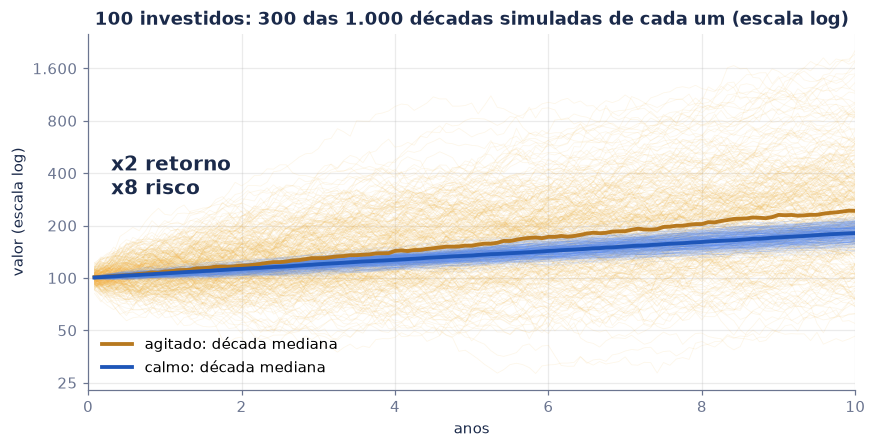

In [5]:
passo = 21                                                      # um ponto por mês
caminho = lambda dec: 100 * np.exp(np.cumsum(np.log1p(dec), axis=1)[:, passo - 1::passo])
cam_ag, cam_ca = caminho(dec_ag), caminho(dec_ca)
t = np.arange(1, 121) / 12
fig, ax = plt.subplots(figsize=(9, 4.2))
for c in cam_ag[:300]:
    ax.plot(t, c, color=AMBER, lw=0.5, alpha=0.12)
for c in cam_ca[:300]:
    ax.plot(t, c, color=LIGHT, lw=0.5, alpha=0.12)
ax.plot(t, np.median(cam_ag, 0), color=GOLD, lw=2.5, label="agitado: década mediana")
ax.plot(t, np.median(cam_ca, 0), color=BLUE, lw=2.5, label="calmo: década mediana")
ax.set_yscale("log"); ax.minorticks_off(); ax.set_yticks([25, 50, 100, 200, 400, 800, 1600], labels=["25", "50", "100", "200", "400", "800", "1.600"])
ax.text(0.3, 520, "x2 retorno\nx8 risco", color=NAVY, weight="bold", fontsize=13, va="top")
ax.set(title="100 investidos: 300 das 1.000 décadas simuladas de cada um (escala log)", xlabel="anos", ylabel="valor (escala log)", xlim=(0, 10))
ax.legend(frameon=False, loc="lower left"); plt.show()

**Leitura.** O leque do agitado é largo: 13,0 % das décadas terminam com menos dinheiro do que começaram, e em 36,5 % delas ele termina abaixo do calmo, mesmo rendendo o dobro na média. Na década mediana, R\$ 1 vira R\$ 2,43 no agitado e R\$ 1,81 no calmo; nas 5 % piores, R\$ 0,74 contra R\$ 1,54. O calmo quase não abre. A pergunta do vídeo é como pôr esses dois leques na mesma régua.

## 2. Os dois passos — eq. (2)

**Passo 1:** subtraia o que a conta segura paga sem risco nenhum ($r_f$, de *risk-free*). O que sobra é o **retorno extra**, o prêmio por aceitar risco. **Passo 2:** divida pela volatilidade:

$$
SR = \frac{\mu - r_f}{\sigma} \tag{2}
$$

William Sharpe propôs a razão em 1966 com o nome de *reward-to-variability ratio*, para comparar fundos mútuos americanos. Em 1994 ele a redefiniu como a média dividida pelo desvio-padrão do **retorno diferencial** $d_t = r_t - r_{f,t}$, que é como se calcula com dados reais (seção 6). No vídeo, a conta segura paga sempre o mesmo, e as duas versões coincidem.

No gráfico de risco (horizontal) contra retorno (vertical), (2) é a **inclinação** da reta que sai do ponto seguro $(0, r_f)$ e passa pelo investimento.

In [6]:
linhas = []
for nome, (ret, risco, sr), alvo in [("agitado", ag, (0.12, 0.24)), ("calmo", ca, (0.06, 0.03)), ("mistura 1/8", mi, None)]:
    linhas.append({"investimento": nome, "retorno total": ret, "seguro": seguro, "passo 1: extra": ret - seguro, "risco": risco,
                   "passo 2: Sharpe (2)": sr, "projetado": (alvo[0] - seguro) / alvo[1] if alvo else np.nan, "retorno / risco (sem o passo 1)": ret / risco})
display(pd.DataFrame(linhas).style.format({"retorno total": P(2), "seguro": P(0), "passo 1: extra": P(2), "risco": P(2),
                                          "passo 2: Sharpe (2)": N(3), "projetado": N(3), "retorno / risco (sem o passo 1)": N(3)}, na_rep="").hide(axis="index"))
print(f"extra do agitado: {pct(ag[0] - seguro, 2)} por {pct(ag[1], 1)} de risco; extra do calmo: {pct(ca[0] - seguro, 2)} por {pct(ca[1], 1)}")
print(f"o calmo paga {br(ca[2] / ag[2], 2)} vezes mais extra por unidade de risco")
assert abs((ag[0] - seguro) / ag[1] - ag[2]) < 1e-15 and round((0.12 - 0.03) / 0.24, 3) == 0.375

investimento,retorno total,seguro,passo 1: extra,risco,passo 2: Sharpe (2),projetado,retorno / risco (sem o passo 1)
agitado,"11,71 %",3 %,"8,71 %","23,99 %","0,363","0,375","0,488"
calmo,"5,98 %",3 %,"2,98 %","3,00 %","0,993","1,000","1,993"
mistura 1/8,"4,09 %",3 %,"1,09 %","3,00 %","0,363",,"1,363"


extra do agitado: 8,71 % por 24,0 % de risco; extra do calmo: 2,98 % por 3,0 %
o calmo paga 2,74 vezes mais extra por unidade de risco


**Por que o passo 1 importa.** Sem subtrair o seguro, a razão retorno/risco da mistura (4,1 % sobre 3,0 %) seria 1,36, quase o triplo da do agitado puro (0,49), só porque a parte em caixa rende 3 % sem risco. A medida mudaria com a quantidade de caixa, que não tem nada a ver com a qualidade do investimento. Com o passo 1, as duas marcam 0,363. A seção 3 mostra que isso não é coincidência.

O "projetado" é o Sharpe dos parâmetros do código: $(12 - 3)/24 = 0{,}375$ e $(6 - 3)/3 = 1$. Os 10.000 anos sorteados dão 0,363 e 0,993; a seção 4 mostra que a diferença é o tamanho esperado do acaso.

## 3. Misturar com caixa não muda o Sharpe — eqs. (3), (4) e (5)

Ponha uma fração $w$ do dinheiro no investimento e o resto, $1 - w$, na conta segura. O retorno extra e o risco da mistura são

$$
\mu_w - r_f = w\,(\mu - r_f), \qquad \sigma_w = |w|\,\sigma \quad\Longrightarrow\quad SR_w = \frac{\mu_w - r_f}{\sigma_w} = SR \quad (w > 0) \tag{3}
$$

O $w$ aparece em cima e embaixo e se cancela. Com $w = 1/8$, o agitado fica tão calmo quanto o calmo (3 % de risco) e rende 4,1 %: menos que os 6 % do calmo, no mesmo risco. Com $w > 1$, você pega dinheiro emprestado à taxa segura e **alavanca**; a conta é a mesma, e o Sharpe também. Todas as misturas de um investimento com caixa ficam na mesma reta, a **linha de alocação de capital**.

Rodando ao contrário: quanto o agitado precisaria render para valer tanto quanto o calmo, no risco dele? É o retorno da reta do calmo na volatilidade do agitado:

$$
\mu^{*} = r_f + SR_{\text{calmo}}\;\sigma_{\text{agitado}} \tag{4}
$$

São os 26,8 % do vídeo. E é exatamente o que rende o **calmo alavancado** até 24 % de volatilidade: cerca de 8 vezes o dinheiro no calmo, com 7 vezes tomado emprestado a 3 %.

In [7]:
seg_d = seguro / 252
tab3 = []
for w_ in [0.125, 0.25, 0.5, 1.0, 2.0, 4.0]:
    r_ = w_ * agitado + (1 - w_) * seg_d
    tab3.append({"w no agitado": w_, "no seguro": 1 - w_, **dict(zip(["retorno", "risco", "Sharpe (3)"], medir(r_)))})
display(pd.DataFrame(tab3).style.format({"w no agitado": N(3), "no seguro": N(3), "retorno": P(2), "risco": P(2), "Sharpe (3)": N(6)}).hide(axis="index"))
assert all(abs(row["Sharpe (3)"] - ag[2]) < 1e-12 for row in tab3)

L = agitado.std() / calmo.std()                       # alavancagem do calmo para ter o risco do agitado
alav = L * calmo + (1 - L) * seg_d                    # L no calmo, L - 1 emprestado a 3 %
ma = medir(alav)
print(f"calmo alavancado {br(L, 3)}x: retorno {pct(ma[0], 2)}, risco {pct(ma[1], 2)}, Sharpe {br(ma[2], 3)}  |  meta (4) = {pct(meta, 2)}")
assert abs(ma[0] - meta) < 1e-12 and abs(ma[2] - ca[2]) < 1e-12 and round(L) == 8

w no agitado,no seguro,retorno,risco,Sharpe (3)
"0,125","0,875","4,09 %","3,00 %","0,362871"
"0,250","0,750","5,18 %","6,00 %","0,362871"
"0,500","0,500","7,35 %","12,00 %","0,362871"
"1,000","0,000","11,71 %","23,99 %","0,362871"
"2,000","−1,000","20,41 %","47,98 %","0,362871"
"4,000","−3,000","37,82 %","95,96 %","0,362871"


calmo alavancado 7,997x: retorno 26,82 %, risco 23,99 %, Sharpe 0,993  |  meta (4) = 26,82 %


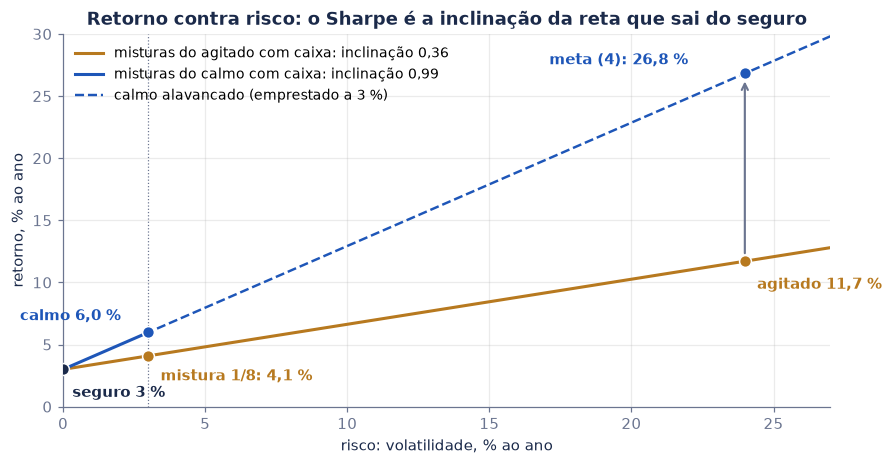

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.4))
xs = np.linspace(0, 27, 50)
ax.plot(xs, 100 * seguro + ag[2] * xs, color=GOLD, lw=2, label=f"misturas do agitado com caixa: inclinação {br(ag[2], 2)}")
ax.plot(xs[xs <= 100 * ca[1]], 100 * seguro + ca[2] * xs[xs <= 100 * ca[1]], color=BLUE, lw=2, label=f"misturas do calmo com caixa: inclinação {br(ca[2], 2)}")
ax.plot(xs[xs >= 100 * ca[1]], 100 * seguro + ca[2] * xs[xs >= 100 * ca[1]], color=BLUE, lw=1.6, ls="--", label="calmo alavancado (emprestado a 3 %)")
pts = [(0, seguro, "seguro 3 %", NAVY, (6, -18)), (ca[1], ca[0], "calmo 6,0 %", BLUE, (-84, 8)), (ag[1], ag[0], "agitado 11,7 %", GOLD, (8, -18)),
       (mi[1], mi[0], "mistura 1/8: 4,1 %", GOLD, (8, -16)), (ma[1], ma[0], "meta (4): 26,8 %", BLUE, (-128, 6))]
for x_, y_, rot, c, off in pts:
    ax.scatter(100 * x_, 100 * y_, s=60, color=c, zorder=4, edgecolor="white")
    ax.annotate(rot, (100 * x_, 100 * y_), off, textcoords="offset points", color=c, weight="bold")
ax.annotate("", xy=(100 * ag[1], 100 * meta - 0.4), xytext=(100 * ag[1], 100 * ag[0] + 0.4), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.4))
ax.axvline(100 * ca[1], color=GREY, lw=0.8, ls=":")
ax.set(title="Retorno contra risco: o Sharpe é a inclinação da reta que sai do seguro", xlabel="risco: volatilidade, % ao ano",
       ylabel="retorno, % ao ano", xlim=(0, 27), ylim=(0, 30))
ax.legend(frameon=False, loc="upper left", fontsize=9); plt.show()

### A carteira de maior Sharpe — eq. (5)

Se dá para alavancar e desalavancar à taxa segura, a escolha se divide em duas etapas independentes (Tobin, 1958): **primeiro**, encontre a carteira de investimentos de risco com o **maior Sharpe**; **depois**, decida quanto pôr nela e quanto deixar no seguro ($w$), de acordo com o risco que você aguenta. A segunda etapa não muda o Sharpe (eq. 3); só a primeira importa para a qualidade.

Com dois investimentos **independentes** (correlação zero), a carteira de maior Sharpe põe em cada um um peso proporcional a $(\mu_i - r_f)/\sigma_i^2$, e o Sharpe dela é

$$
SR_{\max}^2 = SR_1^2 + SR_2^2 \qquad (\rho_{12} = 0) \tag{5}
$$

(a demonstração está na nota técnica). O agitado perde a comparação, mas não é inútil: uma pitada dele, independente do calmo, **melhora** o Sharpe da carteira.

In [9]:
R2 = np.column_stack([agitado, calmo])
mu_ex = R2.mean(0) * 252 - seguro
S = np.cov(R2.T, ddof=0) * 252
z = np.linalg.solve(S, mu_ex)                     # pesos de maior Sharpe, a menos de escala
peso = z / z.sum()
sr_max = math.sqrt(mu_ex @ z)
cart = R2 @ peso
print(f"correlação amostral agitado x calmo: {br(np.corrcoef(R2.T)[0, 1], 4)}")
print(f"carteira de maior Sharpe: {pct(peso[0], 1)} no agitado e {pct(peso[1], 1)} no calmo -> Sharpe {br(sr_max, 3)} (medido: {br(medir(cart)[2], 3)})")
print(f"eq. (5): raiz(0,363² + 0,993²) = {br(math.hypot(ag[2], ca[2]), 3)}  contra o calmo sozinho {br(ca[2], 3)}")
peso_teo = np.array([(0.12 - seguro) / 0.24 ** 2, (0.06 - seguro) / 0.03 ** 2]); peso_teo /= peso_teo.sum()
print(f"pesos pela fórmula com os parâmetros do código: {pct(peso_teo[0], 1)} e {pct(peso_teo[1], 1)}")
print(f"uma pitada do agitado melhora o calmo enquanto a correlação entre eles for menor que SR_agitado/SR_calmo = {br(ag[2] / ca[2], 3)}")
assert abs(medir(cart)[2] - sr_max) < 1e-9 and abs(sr_max - math.hypot(ag[2], ca[2])) < 0.01

correlação amostral agitado x calmo: −0,0002
carteira de maior Sharpe: 4,4 % no agitado e 95,6 % no calmo -> Sharpe 1,057 (medido: 1,057)
eq. (5): raiz(0,363² + 0,993²) = 1,057  contra o calmo sozinho 0,993
pesos pela fórmula com os parâmetros do código: 4,5 % e 95,5 %
uma pitada do agitado melhora o calmo enquanto a correlação entre eles for menor que SR_agitado/SR_calmo = 0,365


## 4. Quanto erra o Sharpe de uma década — eqs. (6) e (7)

O vídeo usa 10.000 anos para ter certeza dos números. Ninguém tem 10.000 anos de dados. Com $T$ observações independentes e normais, Lo (2002) mostra que o Sharpe estimado $\widehat{SR}$ tem erro-padrão

$$
\text{EP}\big(\widehat{SR}\big) \approx \sqrt{\frac{1 + SR^2/2}{T}} \tag{6}
$$

com o Sharpe e $T$ na **mesma** frequência. O "1" vem da incerteza da média; o $SR^2/2$, da incerteza do desvio-padrão. Com dados diários, o Sharpe diário é minúsculo, o segundo termo some e, em unidades anuais, $\text{EP} \approx 1/\sqrt{\text{anos}}$: **uma década de dados diários mede o Sharpe com erro-padrão de 0,32**, qualquer que seja o investimento. Mais pregões não ajudam; só mais anos.

Para o Sharpe ficar a dois erros-padrão de zero (o "t = 2" da estatística), são necessários

$$
\text{anos} \approx \left(\frac{2}{SR}\right)^2 \tag{7}
$$

O calmo se prova em 4,1 anos; o agitado precisa de 30,4.

In [10]:
def sharpe(x, q=252):                       # eq. (2) anualizado com (1), sem retorno seguro (x já é o retorno extra)
    x = np.asarray(x, float)
    return x.mean() / x.std() * math.sqrt(q)

def ep_lo(sr_anual, T, q=252):              # eq. (6) em unidades anuais: T observações de frequência q
    s = sr_anual / math.sqrt(q)
    return math.sqrt(q * (1 + s ** 2 / 2) / T)

sr_dec_ag = (dec_ag.mean(1) * 252 - seguro) / (dec_ag.std(1) * v)          # o medir() de cada década
sr_dec_ca = (dec_ca.mean(1) * 252 - seguro) / (dec_ca.std(1) * v)
tab4 = pd.DataFrame({
    "investimento": ["agitado", "calmo"], "Sharpe em 10.000 anos": [ag[2], ca[2]],
    "média das 1.000 décadas": [sr_dec_ag.mean(), sr_dec_ca.mean()], "desvio entre décadas": [sr_dec_ag.std(), sr_dec_ca.std()],
    "EP pela (6)": [ep_lo(ag[2], dias_dec), ep_lo(ca[2], dias_dec)],
    "5 % das décadas abaixo de": [np.quantile(sr_dec_ag, 0.05), np.quantile(sr_dec_ca, 0.05)],
    "5 % acima de": [np.quantile(sr_dec_ag, 0.95), np.quantile(sr_dec_ca, 0.95)],
    "anos para t = 2, eq. (7)": [(2 / ag[2]) ** 2, (2 / ca[2]) ** 2],
})
display(tab4.style.format({c: N(3) for c in tab4.columns[1:-1]} | {"anos para t = 2, eq. (7)": N(1)}).hide(axis="index"))
ganha = (sr_dec_ag > sr_dec_ca).mean()
prev = Phi(-(ca[2] - ag[2]) / math.hypot(ep_lo(ag[2], dias_dec), ep_lo(ca[2], dias_dec)))
print(f"décadas em que o agitado marca Sharpe maior que o calmo: {pct(ganha)} (a (6) previa {pct(prev)})")
print(f"erro-padrão do Sharpe em 10.000 anos: {br(ep_lo(ag[2], n), 4)} -> o 0,363 do agitado contra o 0,375 projetado está a {br((0.375 - ag[2]) / ep_lo(ag[2], n), 2)} EP")
assert abs(sr_dec_ag.std() - ep_lo(ag[2], dias_dec)) < 0.03 and abs(sr_dec_ca.std() - ep_lo(ca[2], dias_dec)) < 0.03

investimento,Sharpe em 10.000 anos,média das 1.000 décadas,desvio entre décadas,EP pela (6),5 % das décadas abaixo de,5 % acima de,"anos para t = 2, eq. (7)"
agitado,"0,363","0,363","0,312","0,316","−0,131","0,882","30,4"
calmo,"0,993","0,994","0,322","0,317","0,463","1,532","4,1"


décadas em que o agitado marca Sharpe maior que o calmo: 8,5 % (a (6) previa 8,0 %)
erro-padrão do Sharpe em 10.000 anos: 0,0100 -> o 0,363 do agitado contra o 0,375 projetado está a 1,21 EP


O termo $SR^2/2$ aparece quando a frequência é baixa. Com **retornos anuais** (um por ano), o Sharpe anual entra inteiro na (6). A simulação abaixo sorteia 20.000 históricos de $T$ anos para dois Sharpes verdadeiros e compara o desvio do Sharpe estimado com a (6) e com a versão sem o termo:

In [11]:
rng4 = np.random.default_rng(2002)
tab_mc = []
for sr_v in [0.36, 1.0]:
    for T in [10, 30, 100]:
        x = rng4.normal(sr_v, 1.0, (20000, T))          # retornos extras anuais com desvio 1 e média SR
        est = x.mean(1) / x.std(1, ddof=1)
        tab_mc.append({"Sharpe verdadeiro": sr_v, "anos T": T, "média do estimado": est.mean(), "desvio simulado": est.std(),
                       "(6): raiz((1 + SR²/2)/T)": math.sqrt((1 + sr_v ** 2 / 2) / T), "sem o termo: raiz(1/T)": math.sqrt(1 / T)})
mc = pd.DataFrame(tab_mc)
mc["simulado / (6)"] = mc["desvio simulado"] / mc["(6): raiz((1 + SR²/2)/T)"]
display(mc.style.format({"Sharpe verdadeiro": N(2), "anos T": N(0), "média do estimado": N(3), "desvio simulado": N(3),
                         "(6): raiz((1 + SR²/2)/T)": N(3), "sem o termo: raiz(1/T)": N(3), "simulado / (6)": N(3)}).hide(axis="index"))
assert (abs(mc["simulado / (6)"] - 1))[mc["anos T"] >= 100].max() < 0.03 and (mc["simulado / (6)"][mc["anos T"] == 10] > 1.1).all()

Sharpe verdadeiro,anos T,média do estimado,desvio simulado,(6): raiz((1 + SR²/2)/T),sem o termo: raiz(1/T),simulado / (6)
"0,36",10,"0,393","0,378","0,326","0,316","1,158"
"0,36",30,"0,371","0,196","0,188","0,183","1,038"
"0,36",100,"0,362","0,105","0,103","0,100","1,013"
"1,00",10,"1,093","0,468","0,387","0,316","1,210"
"1,00",30,"1,028","0,236","0,224","0,183","1,057"
"1,00",100,"1,008","0,125","0,122","0,100","1,019"


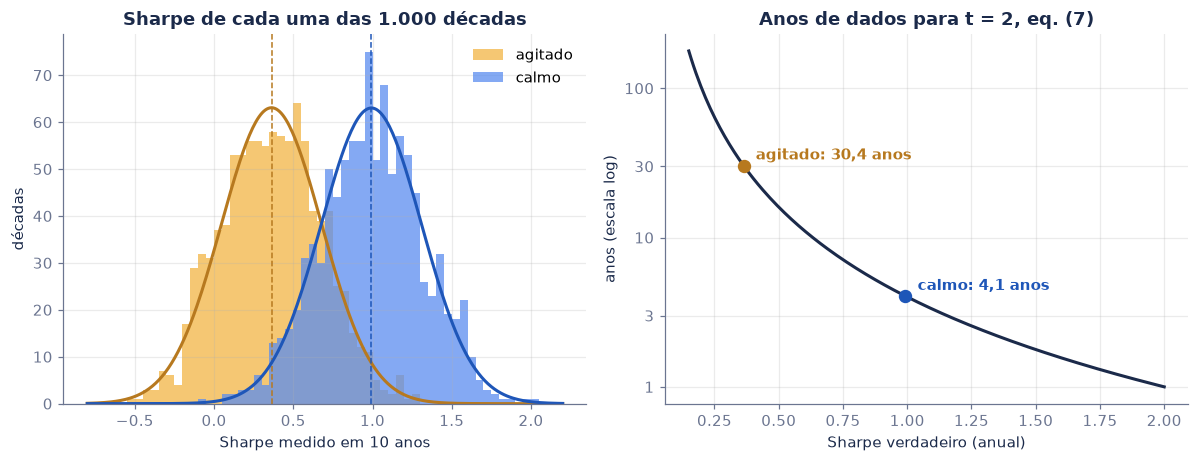

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.3))
bins = np.linspace(-0.8, 2.2, 61)
a1.hist(sr_dec_ag, bins, color=AMBER, alpha=0.75, label="agitado")
a1.hist(sr_dec_ca, bins, color=LIGHT, alpha=0.75, label="calmo")
g = np.linspace(-0.8, 2.2, 300)
for sr_v, c in [(ag[2], GOLD), (ca[2], BLUE)]:
    e = ep_lo(sr_v, dias_dec)
    a1.plot(g, 1000 * (bins[1] - bins[0]) * np.exp(-0.5 * ((g - sr_v) / e) ** 2) / (e * math.sqrt(2 * math.pi)), color=c, lw=2)
    a1.axvline(sr_v, color=c, ls="--", lw=1)
a1.set(title="Sharpe de cada uma das 1.000 décadas", xlabel="Sharpe medido em 10 anos", ylabel="décadas"); a1.legend(frameon=False)
s_ = np.linspace(0.15, 2.0, 200)
a2.plot(s_, (2 / s_) ** 2, color=NAVY, lw=2)
for sr_v, nome, c in [(ag[2], "agitado", GOLD), (ca[2], "calmo", BLUE)]:
    a2.scatter(sr_v, (2 / sr_v) ** 2, color=c, s=60, zorder=3); a2.annotate(f"{nome}: {br((2 / sr_v) ** 2, 1)} anos", (sr_v, (2 / sr_v) ** 2), (8, 4), textcoords="offset points", color=c, weight="bold")
a2.set_yscale("log"); a2.minorticks_off(); a2.set_yticks([1, 3, 10, 30, 100], labels=["1", "3", "10", "30", "100"])
a2.set(title="Anos de dados para t = 2, eq. (7)", xlabel="Sharpe verdadeiro (anual)", ylabel="anos (escala log)")
plt.tight_layout(); plt.show()

**Leitura.** Numa década qualquer, o Sharpe medido do agitado vai de −0,13 a 0,88 (90 % das décadas), e o do calmo, de 0,46 a 1,53. O desvio entre décadas (0,31 e 0,32) é o que a (6) prevê. Em 8,5 % das décadas o agitado **parece** melhor que o calmo (a (6) previa 8,0 %). Quem compara dois gestores por cinco anos de cota está comparando, em boa parte, sorte.

Na simulação com retornos anuais, a (6) acerta a partir de 30 anos de dados; com 10, ela subestima o erro em 16 % a 21 %, porque a fórmula é assintótica (vale para $T$ grande). O Sharpe estimado também sai um pouco **acima** do verdadeiro em amostras curtas.

## 5. Anualizar: a raiz de 252 e a autocorrelação — eq. (8)

A eq. (1) multiplica a média por $q$ e o desvio por $\sqrt q$, e portanto o Sharpe por $\sqrt q$ ($q$ = 252 dias, 12 meses). Isso só vale se os retornos de períodos diferentes forem **independentes**. Se um mês bom tende a ser seguido de outro mês bom (autocorrelação $\rho_k > 0$ na defasagem $k$), a variância anual é maior que 12 vezes a mensal, e a raiz de 12 **exagera** o Sharpe anual. Lo (2002) dá a correção:

$$
SR_{\text{anual}} = \eta(q)\,SR_{\text{período}}, \qquad \eta(q) = \frac{q}{\sqrt{q + 2\sum_{k=1}^{q-1}(q-k)\,\rho_k}} \tag{8}
$$

Com $\rho_k = 0$, $\eta(q) = \sqrt q$. Uma causa comum de $\rho_1 > 0$ é a **cota suave**: ativos sem preço de mercado todo dia (crédito privado, imóveis, participações) são marcados por modelo ou pelo último negócio, e o retorno de hoje carrega um pedaço do de ontem (Getmansky, Lo e Makarov, 2004). A tabela usa o caso mais simples, $\rho_k = \phi^k$ (um AR(1)), e a simulação confere a (8). No fim da célula, um exemplo de cota suave: o retorno publicado é a média do retorno verdadeiro deste mês e do anterior.

In [13]:
def eta(rho, q):                             # eq. (8); rho[k-1] = autocorrelação na defasagem k
    return q / math.sqrt(q + 2 * sum((q - k) * rho[k - 1] for k in range(1, q)))

eta_ar1 = lambda phi, q=12: eta([phi ** k for k in range(1, q)], q)
tab5 = pd.DataFrame({"φ (autocorrelação de 1 mês)": [-0.2, 0.0, 0.1, 0.2, 0.35, 0.5]})
tab5["η(12)"] = tab5.iloc[:, 0].map(eta_ar1)
tab5["raiz de 12"] = math.sqrt(12)
tab5["exagero da raiz de 12"] = tab5["raiz de 12"] / tab5["η(12)"] - 1
display(tab5.style.format({"φ (autocorrelação de 1 mês)": N(2), "η(12)": N(3), "raiz de 12": N(3),
                           "exagero da raiz de 12": lambda x: ("+" if x > 5e-4 else "") + pct(round(x, 3) + 0.0, 1)}).hide(axis="index"))

rng5 = np.random.default_rng(12)
def anos_ar1(phi, anos=100000, mu=0.004, sd=0.01, aquece=48):
    e = rng5.normal(0, sd * math.sqrt(1 - phi ** 2), (anos, aquece + 12))
    x = np.zeros_like(e); x[:, 0] = rng5.normal(0, sd, anos)
    for j in range(1, aquece + 12):
        x[:, j] = phi * x[:, j - 1] + e[:, j]
    return mu + x[:, aquece:]                   # 12 meses estacionários por "ano"

sim5 = []
for phi in [0.1, 0.35, 0.5]:
    m_ = anos_ar1(phi)
    sr_m = m_.mean() / m_.std()
    anual = m_.sum(1)
    sim5.append({"φ": phi, "Sharpe mensal": sr_m, "anual ingênuo (raiz de 12)": math.sqrt(12) * sr_m,
                 "anual pela (8)": eta_ar1(phi) * sr_m, "anual verdadeiro (somas de 12 meses)": anual.mean() / anual.std()})
sim5 = pd.DataFrame(sim5)
display(sim5.style.format(N(3)).hide(axis="index"))
assert (abs(sim5["anual pela (8)"] / sim5["anual verdadeiro (somas de 12 meses)"] - 1) < 0.02).all()

# cota suave: o retorno publicado é a média do retorno verdadeiro deste mês e do anterior, θ = (0,5; 0,5)
th = np.array([0.5, 0.5])
rho1_s = th[0] * th[1] / (th ** 2).sum()
infla_m = 1 / math.sqrt((th ** 2).sum())                      # o Sharpe mensal publicado é maior por este fator
eta_s = eta([rho1_s] + [0.0] * 10, 12)
print(f"cota suave θ = (0,5; 0,5): ρ1 = {br(rho1_s, 2)}, volatilidade publicada = {br(1 / infla_m, 3)} da verdadeira, Sharpe mensal publicado {br(infla_m, 3)}x o verdadeiro")
print(f"  anual pela raiz de 12: {br(infla_m, 3)}x o verdadeiro (exagero {pct(infla_m - 1, 1)});  pela (8): {br(eta_s * infla_m / math.sqrt(12), 3)}x")
print(f"limite para q grande no AR(1): η(q)/raiz(q) -> raiz((1 - φ)/(1 + φ)); com φ = 0,35, exagero de {pct(1 / math.sqrt(0.65 / 1.35) - 1, 1)} (com q = 12: {pct(math.sqrt(12) / eta_ar1(0.35) - 1, 1)})")

φ (autocorrelação de 1 mês),η(12),raiz de 12,exagero da raiz de 12
"−0,20","4,171","3,464","−16,9 %"
"0,00","3,464","3,464","0,0 %"
"0,10","3,160","3,464","+9,6 %"
"0,20","2,879","3,464","+20,3 %"
"0,35","2,488","3,464","+39,2 %"
"0,50","2,121","3,464","+63,3 %"


φ,Sharpe mensal,anual ingênuo (raiz de 12),anual pela (8),anual verdadeiro (somas de 12 meses)
"0,100","0,398","1,379","1,258","1,257"
"0,350","0,401","1,389","0,998","0,996"
"0,500","0,400","1,385","0,848","0,849"


cota suave θ = (0,5; 0,5): ρ1 = 0,50, volatilidade publicada = 0,707 da verdadeira, Sharpe mensal publicado 1,414x o verdadeiro
  anual pela raiz de 12: 1,414x o verdadeiro (exagero 41,4 %);  pela (8): 1,022x
limite para q grande no AR(1): η(q)/raiz(q) -> raiz((1 - φ)/(1 + φ)); com φ = 0,35, exagero de 44,1 % (com q = 12: 39,2 %)


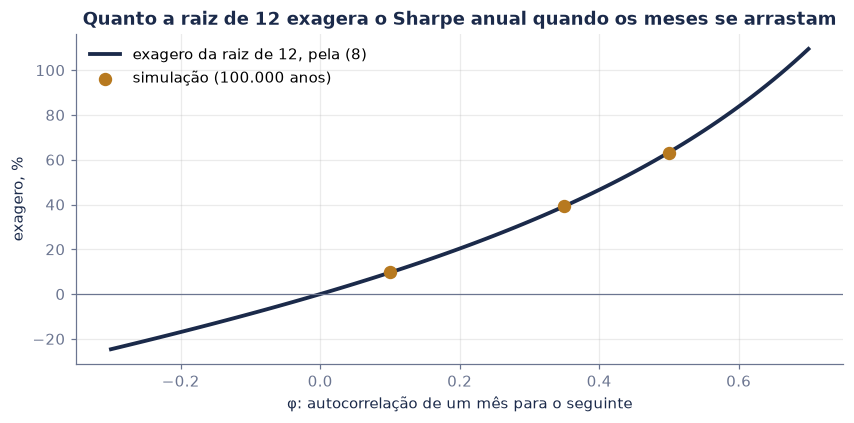

In [14]:
ph = np.linspace(-0.3, 0.7, 101)
fig, ax = plt.subplots(figsize=(9, 3.9))
ax.plot(ph, 100 * (math.sqrt(12) / np.array([eta_ar1(p) for p in ph]) - 1), color=NAVY, lw=2.5, label="exagero da raiz de 12, pela (8)")
ax.scatter(sim5["φ"], 100 * (sim5["anual ingênuo (raiz de 12)"] / sim5["anual verdadeiro (somas de 12 meses)"] - 1), color=GOLD, s=60, zorder=3, label="simulação (100.000 anos)")
ax.axhline(0, color=GREY, lw=0.8)
ax.set(title="Quanto a raiz de 12 exagera o Sharpe anual quando os meses se arrastam", xlabel="φ: autocorrelação de um mês para o seguinte", ylabel="exagero, %")
ax.legend(frameon=False); plt.show()

## 6. No Brasil: o Ibovespa contra o CDI desde 1995 — eq. (9)

No Brasil, a "conta segura" do vídeo é o **CDI**: o que qualquer investidor ganha num fundo DI, num CDB de liquidez diária ou no Tesouro Selic, quase sem oscilar. E ele não é 3 %: desde 1995, a média passa de 14 % ao ano. O retorno extra do Ibovespa é medido **dia a dia** contra o CDI daquele dia (a definição de Sharpe, 1994), com o CDI acumulado entre dois pregões consecutivos. O Ibovespa já é um índice de retorno total (reinveste os dividendos). Começamos em 1995, depois da troca de moeda.

Primeiro, a conferência dos dados: datas repetidas e os maiores movimentos de um dia (todos são episódios conhecidos: a desvalorização de janeiro de 1999, as crises de 1998, 2008 e 2020).

In [15]:
ib = pd.read_csv("dados/ibovespa.csv", parse_dates=["data"]).set_index("data")["ibov"]
cdi = pd.read_csv("dados/cdi_diario.csv", parse_dates=["data"]).set_index("data")["cdi_pct_ad"] / 100
print(f"Ibovespa: {br(len(ib), 0)} pregões, {ib.index.min():%d/%m/%Y} a {ib.index.max():%d/%m/%Y}, datas repetidas: {ib.index.duplicated().sum()}")
print(f"CDI: {br(len(cdi), 0)} dias úteis, {cdi.index.min():%d/%m/%Y} a {cdi.index.max():%d/%m/%Y}, datas repetidas: {cdi.index.duplicated().sum()}")
cdi_aa = (1 + cdi) ** 252 - 1
print(f"CDI ao ano: de {pct(cdi_aa.min(), 2)} ({cdi_aa.idxmin():%m/%Y}) a {pct(cdi_aa.max(), 1)} ({cdi_aa.idxmax():%m/%Y}); em 16/10/2026, {pct(cdi_aa.iloc[-1], 2)}")
r_ib = ib.pct_change().dropna()
print("maiores movimentos de um dia:", ", ".join(f"{d:%d/%m/%Y} {pct(x, 1)}" for d, x in r_ib.reindex(r_ib.abs().sort_values(ascending=False).index[:6]).items()))
assert ib.index.is_monotonic_increasing and not ib.index.duplicated().any() and r_ib.abs().max() < 0.4

G = (1 + cdi).cumprod().shift(1).fillna(1.0)          # quanto R$ 1 aplicado no CDI vale no fim de cada dia (a taxa de d rende de d para d+1)
def cdi_entre(datas):                                 # CDI acumulado entre duas datas consecutivas da lista
    g = G.reindex(G.index.union(datas)).ffill().reindex(datas)
    return g.pct_change()
cdi_ib = cdi_entre(ib.index).reindex(r_ib.index)                    # CDI ganho entre um pregão e o seguinte
ex_ib = r_ib - cdi_ib                                                # retorno extra diário do Ibovespa
assert ex_ib.notna().all()
print(f"{br(len(ex_ib), 0)} retornos extras diários, de {ex_ib.index.min():%d/%m/%Y} a {ex_ib.index.max():%d/%m/%Y}; {br(len(ex_ib) / ((ex_ib.index[-1] - ex_ib.index[0]).days / 365.25), 1)} pregões por ano")

Ibovespa: 7.875 pregões, 02/01/1995 a 16/10/2026, datas repetidas: 0
CDI: 7.980 dias úteis, 02/01/1995 a 16/10/2026, datas repetidas: 0
CDI ao ano: de 1,90 % (08/2020) a 87,3 % (03/1995); em 16/10/2026, 13,65 %
maiores movimentos de um dia: 15/01/1999 33,4 %, 10/03/1995 25,6 %, 15/09/1998 18,7 %, 10/09/1998 −15,8 %, 27/10/1997 −15,0 %, 12/03/2020 −14,8 %
7.874 retornos extras diários, de 03/01/1995 a 16/10/2026; 247,7 pregões por ano


O erro-padrão vem de duas formas: pela (6), que supõe dias independentes, e por **bootstrap em blocos circulares** (Künsch, 1989; Politis e Romano, 1992): sorteamos blocos de 21 pregões seguidos, com reposição, até montar uma história do mesmo tamanho, e medimos o Sharpe de cada uma de 2.000 histórias. Os blocos preservam o que os dias têm de dependência (volatilidade que vem em ondas, por exemplo).

In [16]:
def boot_sharpe(x, q=252, b=21, B=2000, semente=0):
    # Sharpe de B histórias montadas com blocos circulares de b observações seguidas
    x = np.asarray(x, float); T = len(x); rng_b = np.random.default_rng(semente)
    k, out = -(-T // b), np.empty(B)
    for i in range(0, B, 200):
        st = rng_b.integers(0, T, (min(200, B - i), k))
        xs = x[((st[:, :, None] + np.arange(b)) % T).reshape(len(st), -1)[:, :T]]
        out[i:i + len(st)] = xs.mean(1) / xs.std(1) * math.sqrt(q)
    return out

per = [("1995–2004", "1995", "2004"), ("2005–2014", "2005", "2014"), ("2015–2026", "2015", "2026"), ("1995–2026", "1995", "2026")]
tab6 = []
for nome, a, b_ in per:
    x = ex_ib[a:b_]
    bs = boot_sharpe(x.values, semente=6)
    anos_ = (x.index[-1] - x.index[0]).days / 365.25
    tab6.append({"período": nome, "anos": anos_, "Ibovespa (média ao ano)": r_ib[a:b_].mean() * 252, "CDI (média ao ano)": cdi_ib[a:b_].mean() * 252,
                 "extra ao ano": x.mean() * 252, "volatilidade": x.std() * math.sqrt(252), "Sharpe": sharpe(x),
                 "EP pela (6)": ep_lo(sharpe(x), len(x)), "EP bootstrap": bs.std(), "IC 95 %: de": np.quantile(bs, 0.025), "até": np.quantile(bs, 0.975)})
tab6 = pd.DataFrame(tab6)
display(tab6.style.format({"anos": N(1), "Ibovespa (média ao ano)": P(1), "CDI (média ao ano)": P(1), "extra ao ano": P(1), "volatilidade": P(1),
                           "Sharpe": N(2), "EP pela (6)": N(2), "EP bootstrap": N(2), "IC 95 %: de": N(2), "até": N(2)}).hide(axis="index"))
sr_ib = tab6.iloc[-1]["Sharpe"]
print("Sharpe por período, com 3 casas:", ", ".join(f"{p_} {br(s_, 3)}" for p_, s_ in zip(tab6["período"], tab6["Sharpe"])))
print(f"anos para provar o Sharpe de 1995–2026 pela (7): {br((2 / sr_ib) ** 2, 0)}")
assert (tab6["IC 95 %: de"] < 0).all() and (tab6["até"] > 0).all()        # nenhum período distingue o Ibovespa do CDI
for b in [5, 63]:
    print(f"bootstrap com blocos de {b} pregões, 1995–2026: EP {br(boot_sharpe(ex_ib.values, b=b, semente=6).std(), 3)}")

período,anos,Ibovespa (média ao ano),CDI (média ao ano),extra ao ano,volatilidade,Sharpe,EP pela (6),EP bootstrap,IC 95 %: de,até
1995–2004,"10,0","26,5 %","22,5 %","4,0 %","40,6 %","0,10","0,32","0,30","−0,47","0,68"
2005–2014,"10,0","10,7 %","11,2 %","−0,5 %","28,8 %","−0,02","0,32","0,29","−0,57","0,54"
2015–2026,"11,8","14,9 %","9,7 %","5,2 %","23,1 %","0,22","0,29","0,31","−0,37","0,83"
1995–2026,"31,8","17,2 %","14,2 %","3,0 %","31,3 %","0,10","0,18","0,17","−0,25","0,42"


Sharpe por período, com 3 casas: 1995–2004 0,098, 2005–2014 −0,017, 2015–2026 0,224, 1995–2026 0,097
anos para provar o Sharpe de 1995–2026 pela (7): 427


bootstrap com blocos de 5 pregões, 1995–2026: EP 0,169


bootstrap com blocos de 63 pregões, 1995–2026: EP 0,159


**Leitura.** Em nenhum dos três períodos, nem nos 31,8 anos juntos, o intervalo de 95 % exclui o zero. O Sharpe de 1995 a 2026, 0,10, está a pouco mais de meio erro-padrão de zero, e prová-lo pela (7) exigiria 427 anos de dados. A década de 2005 a 2014 foi perdida (−0,02); a de 2015 a 2026 foi a melhor (0,22) e, ainda assim, não se distingue de zero. O erro-padrão pela (6) e pelo bootstrap quase coincidem (0,18 e 0,17), e trocar o bloco de 21 por 5 ou 63 pregões quase não mexe nele: os dias do Ibovespa são quase independentes na média.

**Um Sharpe positivo que perdeu do CDI.** O Sharpe de 1995 a 2026 é positivo, mas, em reais acumulados, quem ficou no CDI terminou na frente. O Sharpe usa a média **aritmética** dos retornos; o patrimônio cresce pela média **geométrica**, que é menor quanto maior a volatilidade (o arrasto da volatilidade). Com $g$ a taxa de crescimento composta,

$$
g - r_f \approx (\mu - r_f) - \frac{\sigma^2}{2} = \sigma\left(SR - \frac{\sigma}{2}\right) \tag{9}
$$

Para um investimento ganhar do CDI **no acumulado**, não basta Sharpe positivo: é preciso $SR > \sigma/2$. Com a volatilidade do Ibovespa desde 1995 (31,3 % ao ano), isso é um Sharpe de 0,16. O Ibovespa teve 0,10.

In [17]:
anos_t = (ib.index[-1] - ib.index[0]).days / 365.25
f_ib, f_cdi = ib.iloc[-1] / ib.iloc[0], (1 + cdi_ib).prod()
x = ex_ib
sig, sr_ = x.std() * math.sqrt(252), sharpe(x)
print(f"de {ib.index[0]:%d/%m/%Y} a {ib.index[-1]:%d/%m/%Y} ({br(anos_t, 1)} anos): Ibovespa x{br(f_ib, 1)}, CDI x{br(f_cdi, 1)}")
print(f"crescimento composto: Ibovespa {pct(f_ib ** (1 / anos_t) - 1, 2)} ao ano, CDI {pct(f_cdi ** (1 / anos_t) - 1, 2)} ao ano")
print(f"diferença em log por ano: {pct(math.log(f_ib / f_cdi) / anos_t, 2)};  pela (9): {pct(sig * (sr_ - sig / 2), 2)}  (σ = {pct(sig, 1)}, SR = {br(sr_, 3)})")
print(f"Sharpe mínimo para empatar no acumulado, σ/2 = {br(sig / 2, 3)}")
print(f"alavancagem de crescimento máximo (Kelly) L* = SR/σ = {br(sr_ / sig, 2)}: {pct(sr_ / sig, 0)} no Ibovespa e o resto no CDI, ganhando SR²/2 = {pct(sr_ ** 2 / 2, 2)} ao ano sobre o CDI")
q_ef = len(ex_ib) / anos_t
print(f"{br(q_ef, 1)} pregões por ano em vez de 252: anualizar com 252 aumenta a média em {pct(252 / q_ef - 1, 1)}, o desvio em {pct(math.sqrt(252 / q_ef) - 1, 1)} e o Sharpe em {pct(math.sqrt(252 / q_ef) - 1, 1)}")
assert f_ib < f_cdi and sr_ > 0 and sr_ < sig / 2

de 02/01/1995 a 16/10/2026 (31,8 anos): Ibovespa x47,8, CDI x84,5
crescimento composto: Ibovespa 12,93 % ao ano, CDI 14,98 % ao ano
diferença em log por ano: −1,79 %;  pela (9): −1,86 %  (σ = 31,3 %, SR = 0,097)
Sharpe mínimo para empatar no acumulado, σ/2 = 0,156
alavancagem de crescimento máximo (Kelly) L* = SR/σ = 0,31: 31 % no Ibovespa e o resto no CDI, ganhando SR²/2 = 0,47 % ao ano sobre o CDI
247,7 pregões por ano em vez de 252: anualizar com 252 aumenta a média em 1,7 %, o desvio em 0,9 % e o Sharpe em 0,9 %


### Janelas de 5 anos e o teste de Lo (2002) com dado mensal

Um Sharpe de cinco anos tem erro-padrão de $1/\sqrt 5 \approx 0{,}45$ pela (6). O gráfico mostra o Sharpe de cada janela de 5 anos (1.260 pregões) e a faixa de $\pm 1{,}96$ erro-padrão em volta de zero: dentro dela, a janela não distingue o Ibovespa do CDI.

6.615 janelas de 5 anos (a primeira termina em 07/02/2000); Sharpe negativo em 37,9 % delas
menor: −0,85 (janela até 01/2016);  maior: 1,07 (até 11/2007);  última: 0,11
erro-padrão de um Sharpe de 5 anos pela (6): 0,447;  fora da faixa ±0,88: 1,9 % das janelas


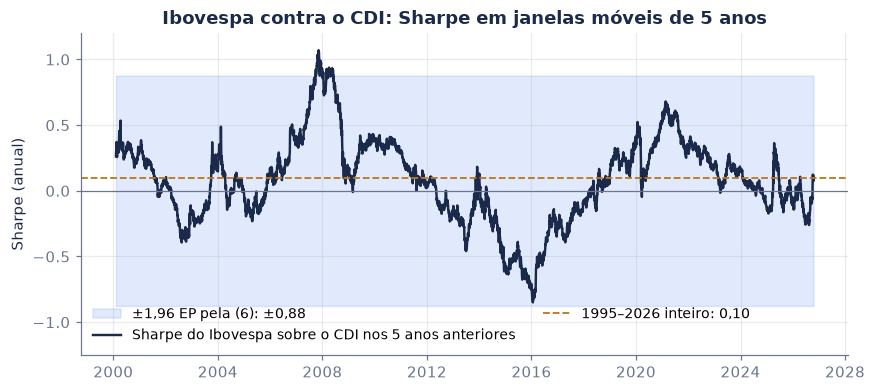

In [18]:
jan = 1260
rol = (x.rolling(jan).mean() / x.rolling(jan).std(ddof=0) * math.sqrt(252)).dropna()
faixa = 1.96 * ep_lo(0.0, jan)
print(f"{br(len(rol), 0)} janelas de 5 anos (a primeira termina em {rol.index[0]:%d/%m/%Y}); Sharpe negativo em {pct((rol < 0).mean())} delas")
print(f"menor: {br(rol.min(), 2)} (janela até {rol.idxmin():%m/%Y});  maior: {br(rol.max(), 2)} (até {rol.idxmax():%m/%Y});  última: {br(rol.iloc[-1], 2)}")
print(f"erro-padrão de um Sharpe de 5 anos pela (6): {br(ep_lo(0.0, jan), 3)};  fora da faixa ±{br(faixa, 2)}: {pct((rol.abs() > faixa).mean())} das janelas")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(rol.index, -faixa, faixa, color=LIGHT, alpha=0.18, label=f"±1,96 EP pela (6): ±{br(faixa, 2)}")
ax.plot(rol.index, rol, color=NAVY, lw=1.6, label="Sharpe do Ibovespa sobre o CDI nos 5 anos anteriores")
ax.axhline(0, color=GREY, lw=0.8); ax.axhline(sr_, color=GOLD, ls="--", lw=1.2, label=f"1995–2026 inteiro: {br(sr_, 2)}")
ax.set(title="Ibovespa contra o CDI: Sharpe em janelas móveis de 5 anos", ylabel="Sharpe (anual)", ylim=(-1.25, 1.2))
ax.legend(frameon=False, fontsize=9, loc="lower left", ncol=2); plt.show()

Lo (2002) aplica a (8) a dados **mensais**. Com o Ibovespa, nenhuma das 11 autocorrelações mensais de fev/1995 a set/2026 sai da faixa de $\pm 2/\sqrt T$; somadas, elas são levemente negativas, e a (8) até **aumenta** o Sharpe anual, de 0,079 para 0,089. Para o Ibovespa, a raiz de 12 não engana. O teste importa para o que tem cota suave (seção 9).

In [19]:
gm = G.resample("ME").last()
im = ib.resample("ME").last()
exm = (im.pct_change() - gm.pct_change()).dropna()["1995-02":"2026-09"]
rho = [exm.autocorr(k) for k in range(1, 12)]
sr_m = exm.mean() / exm.std(ddof=0)
print(f"{br(len(exm), 0)} meses; autocorrelações 1 a 11: {', '.join(br(r, 2) for r in rho)}  (faixa ±2/raiz(T) = ±{br(2 / math.sqrt(len(exm)), 2)})")
print(f"η(12) = {br(eta(rho, 12), 3)} contra raiz de 12 = {br(math.sqrt(12), 3)}")
print(f"Sharpe anual: ingênuo {br(math.sqrt(12) * sr_m, 3)}, pela (8) {br(eta(rho, 12) * sr_m, 3)};  EP mensal pela (6): {br(ep_lo(math.sqrt(12) * sr_m, len(exm), 12), 3)}, bootstrap (blocos de 6 meses): {br(boot_sharpe(exm.values, q=12, b=6, semente=6).std(), 3)}")

380 meses; autocorrelações 1 a 11: 0,02, −0,05, −0,03, 0,03, −0,09, −0,06, 0,02, −0,03, −0,05, 0,08, 0,05  (faixa ±2/raiz(T) = ±0,10)
η(12) = 3,887 contra raiz de 12 = 3,464
Sharpe anual: ingênuo 0,079, pela (8) 0,089;  EP mensal pela (6): 0,178, bootstrap (blocos de 6 meses): 0,168


## 7. No Brasil: 38 ações da B3 desde 2015

Sharpe de cada ação sobre o CDI, com preços ajustados por dividendos e desdobramentos, de 02/01/2015 a 09/10/2026, com intervalo de 95 % por bootstrap em blocos de 21 pregões. As **mesmas** histórias sorteadas valem para todas as ações, para preservar o que elas têm em comum no mesmo dia. A pergunta: em quantas o Sharpe é **estatisticamente diferente de zero**?

In [20]:
px = pd.read_csv("dados/acoes_b3.csv", parse_dates=["data"]).set_index("data")
assert not px.index.duplicated().any() and px.notna().all().all()
ex_ac = px.pct_change().sub(cdi_entre(px.index), axis=0).iloc[1:]
anos_ac = (ex_ac.index[-1] - ex_ac.index[0]).days / 365.25
print(f"{px.shape[1] - 1} ações + IBOV, {br(len(ex_ac), 0)} pregões, {br(anos_ac, 1)} anos ({ex_ac.index[0]:%d/%m/%Y} a {ex_ac.index[-1]:%d/%m/%Y})")

X, T = ex_ac.values, len(ex_ac)
rng7, b, B = np.random.default_rng(38), 21, 2000
k = -(-T // b)
bs7 = np.empty((B, X.shape[1]))
for i in range(0, B, 100):
    st = rng7.integers(0, T, (100, k))
    xs = X[((st[:, :, None] + np.arange(b)) % T).reshape(100, -1)[:, :T]]
    bs7[i:i + 100] = xs.mean(1) / xs.std(1) * math.sqrt(252)
sr7 = pd.DataFrame({"Sharpe": [sharpe(X[:, j]) for j in range(X.shape[1])], "EP (6)": [ep_lo(sharpe(X[:, j]), T) for j in range(X.shape[1])],
                    "de": np.quantile(bs7, 0.025, axis=0), "até": np.quantile(bs7, 0.975, axis=0)}, index=ex_ac.columns)
acoes = sr7.drop(index="IBOV")
sig_ = acoes[(acoes["de"] > 0) | (acoes["até"] < 0)]
print(f"Sharpe positivo: {(acoes.Sharpe > 0).sum()} de {len(acoes)};  mediana {br(acoes.Sharpe.median(), 2)};  IBOV {br(sr7.loc['IBOV', 'Sharpe'], 2)}")
print(f"IC 95 % sem o zero: {len(sig_)} de {len(acoes)} -> " + ", ".join(f"{t} {br(s, 2)} [{br(a, 2)}; {br(z_, 2)}]" for t, (s, a, z_) in sig_[["Sharpe", "de", "até"]].iterrows()))
print(f"se nenhuma tivesse Sharpe verdadeiro diferente de zero, o acaso daria em média {br(0.05 * len(acoes), 1)} 'significativas'")
print(f"EP típico: (6) {br(acoes['EP (6)'].median(), 3)}, bootstrap {br(np.median(bs7.std(0)[:-1]), 3)}")
def quantil(p, a=-10.0, b=10.0):                     # inversa da normal por bisseção
    for _ in range(100):
        m_ = (a + b) / 2
        a, b = (m_, b) if Phi(m_) < p else (a, m_)
    return (a + b) / 2
z_bonf = quantil(1 - 0.025 / len(acoes))
t_prio = acoes.loc["PRIO3", "Sharpe"] / acoes.loc["PRIO3", "EP (6)"]
print(f"PRIO3: t = Sharpe/EP = {br(t_prio, 2)}; com a correção de Bonferroni para 38 testes, o corte bilateral de 5 % sobe de 1,96 para {br(z_bonf, 2)}")

38 ações + IBOV, 2.922 pregões, 11,8 anos (05/01/2015 a 09/10/2026)


Sharpe positivo: 35 de 38;  mediana 0,30;  IBOV 0,24
IC 95 % sem o zero: 1 de 38 -> PRIO3 0,82 [0,24; 1,36]
se nenhuma tivesse Sharpe verdadeiro diferente de zero, o acaso daria em média 1,9 'significativas'
EP típico: (6) 0,294, bootstrap 0,289
PRIO3: t = Sharpe/EP = 2,77; com a correção de Bonferroni para 38 testes, o corte bilateral de 5 % sobe de 1,96 para 3,21


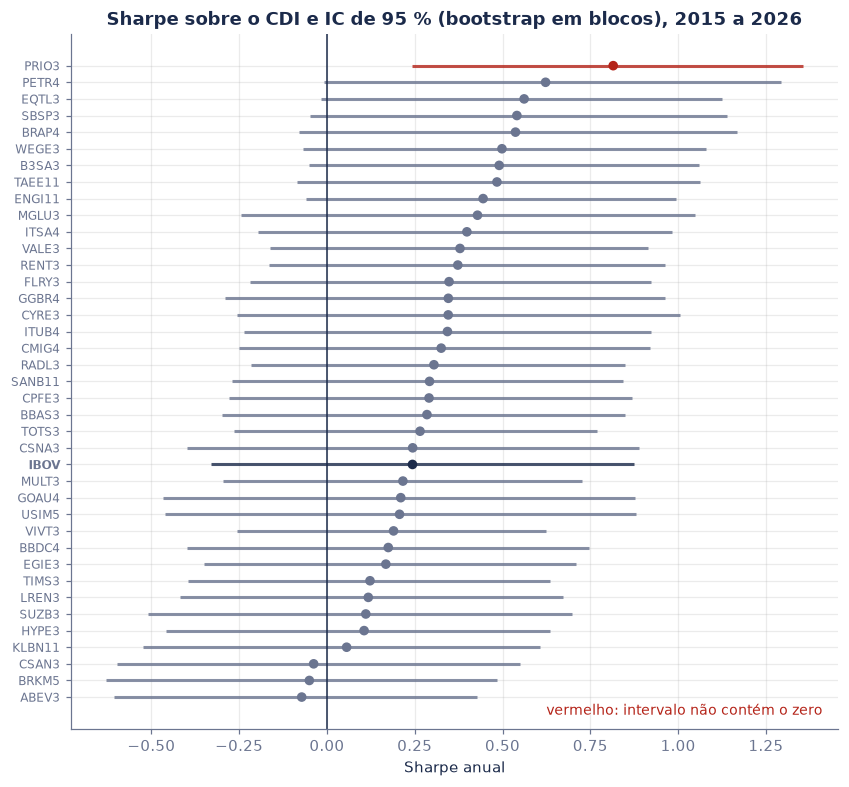

In [21]:
o = sr7.sort_values("Sharpe")
fig, ax = plt.subplots(figsize=(9, 8.2))
y = np.arange(len(o))
cores = [RED if (a > 0 or z_ < 0) else (NAVY if t == "IBOV" else GREY) for t, a, z_ in zip(o.index, o["de"], o["até"])]
ax.hlines(y, o["de"], o["até"], color=cores, lw=2, alpha=0.8)
ax.scatter(o["Sharpe"], y, color=cores, s=28, zorder=3)
ax.axvline(0, color=NAVY, lw=1)
ax.set_yticks(y); ax.set_yticklabels(o.index, fontsize=8)
for lab in ax.get_yticklabels():
    if lab.get_text() == "IBOV":
        lab.set_weight("bold")
ax.set(title="Sharpe sobre o CDI e IC de 95 % (bootstrap em blocos), 2015 a 2026", xlabel="Sharpe anual")
ax.text(0.98, 0.02, "vermelho: intervalo não contém o zero", transform=ax.transAxes, ha="right", color=RED, fontsize=9)
plt.show()

**O Sharpe persiste?** Se o Sharpe medisse uma qualidade estável da ação, quem foi bem de 2015 a 2020 iria bem de 2021 a 2026. A correlação de postos (Spearman) entre as duas metades:

In [22]:
h1, h2 = ex_ac[:"2020"].drop(columns="IBOV"), ex_ac["2021":].drop(columns="IBOV")
s1, s2 = h1.apply(sharpe), h2.apply(sharpe)
spear = s1.rank().corr(s2.rank())
top1, top2 = set(s1.nlargest(10).index), set(s2.nlargest(10).index)
print(f"Sharpe 2015–2020 x 2021–2026: correlação de postos {br(spear, 2)};  das 10 melhores da 1ª metade, {len(top1 & top2)} ficaram entre as 10 melhores da 2ª")
print(f"mediana: {br(s1.median(), 2)} na 1ª metade, {br(s2.median(), 2)} na 2ª;  erro-padrão do Sharpe de cada metade pela (6): {br(ep_lo(s1.median(), len(h1)), 2)} e {br(ep_lo(s2.median(), len(h2)), 2)}")

Sharpe 2015–2020 x 2021–2026: correlação de postos −0,19;  das 10 melhores da 1ª metade, 2 ficaram entre as 10 melhores da 2ª
mediana: 0,48 na 1ª metade, 0,08 na 2ª;  erro-padrão do Sharpe de cada metade pela (6): 0,41 e 0,42


**Leitura.** Desde 2015, 35 das 38 ações tiveram Sharpe positivo sobre o CDI, com mediana de 0,30. Mas só **uma**, PRIO3 (0,82), tem intervalo de 95 % que não contém o zero, e o acaso sozinho daria, em média, 1,9. Corrigindo para 38 testes (Bonferroni), o corte do $t$ sobe de 1,96 para 3,21, e nem PRIO3 passa ($t$ = 2,77). Em 11,8 anos, o erro-padrão do Sharpe de uma ação é de 0,29: um Sharpe de 0,30 está a um erro-padrão de zero. E o Sharpe **não persiste**: a correlação de postos entre 2015–2020 e 2021–2026 é **negativa** (−0,19), e só 2 das 10 melhores da primeira metade ficaram entre as 10 melhores da segunda. O Sharpe passado de uma ação diz pouco sobre o futuro.

Duas ressalvas honestas. **Sobrevivência:** estas 38 são ações grandes **hoje**; empresas que quebraram ou encolheram desde 2015 não estão na lista, e isso puxa os Sharpes para cima. **Muitos testes:** com 38 intervalos de 95 %, cerca de dois excluiriam o zero só por acaso.

## 8. Mesa de operações: alavancar não é de graça — eq. (10)

A eq. (3) supõe que se pega dinheiro emprestado **à taxa segura**. Na vida real, quem toma emprestado paga um spread $s$ acima dela. Com alavancagem $L > 1$ (você investe $L$ vezes o capital e deve $L - 1$), o retorno extra perde $(L-1)\,s$:

$$
SR_L = \frac{L(\mu - r_f) - (L-1)\,s}{L\,\sigma} = SR - \frac{L-1}{L}\,\frac{s}{\sigma} \tag{10}
$$

A reta da seção 3 **dobra** no ponto $L = 1$ e fica menos inclinada à direita. No vídeo, a meta de 26,8 % é o calmo alavancado cerca de 8 vezes. Quanto de spread derruba esse calmo alavancado ao nível do agitado?

In [23]:
sr_L = lambda sr, L, s, sig: sr - (L - 1) / L * s / sig            # eq. (10)
s_emp = (ca[2] - ag[2]) * L * ca[1] / (L - 1)                       # spread que iguala o calmo alavancado ao agitado
tab8 = pd.DataFrame({"spread sobre o seguro": [0.0, 0.005, 0.01, 0.02, s_emp, 0.03]})
tab8["Sharpe do calmo alavancado (10)"] = [sr_L(ca[2], L, s, ca[1]) for s in tab8.iloc[:, 0]]
tab8["retorno no risco do agitado"] = seguro + tab8["Sharpe do calmo alavancado (10)"] * ag[1]
display(tab8.style.format({"spread sobre o seguro": P(2), "Sharpe do calmo alavancado (10)": N(3), "retorno no risco do agitado": P(1)}).hide(axis="index"))
print(f"com spread de {pct(s_emp, 2)} ao ano, o calmo alavancado {br(L, 2)}x rende {pct(seguro + sr_L(ca[2], L, s_emp, ca[1]) * ag[1], 1)}: o mesmo que o agitado")
assert abs(sr_L(ca[2], L, s_emp, ca[1]) - ag[2]) < 1e-12

spread sobre o seguro,Sharpe do calmo alavancado (10),retorno no risco do agitado
"0,00 %","0,993","26,8 %"
"0,50 %","0,847","23,3 %"
"1,00 %","0,701","19,8 %"
"2,00 %","0,410","12,8 %"
"2,16 %","0,363","11,7 %"
"3,00 %","0,118","5,8 %"


com spread de 2,16 % ao ano, o calmo alavancado 8,00x rende 11,7 %: o mesmo que o agitado


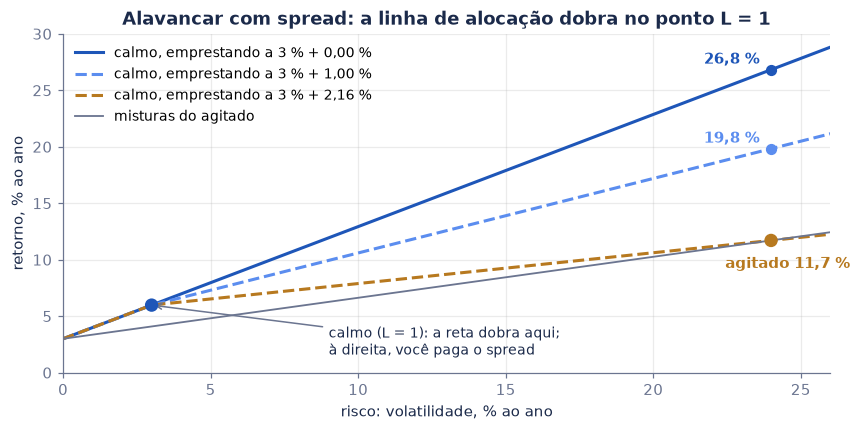

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.0))
xs = np.linspace(0, 26, 100)
for s, c, ls in [(0.0, BLUE, "-"), (0.01, LIGHT, "--"), (s_emp, GOLD, "--")]:
    ys = np.where(xs <= 100 * ca[1], 100 * seguro + ca[2] * xs, 100 * ca[0] + (ca[2] - s / ca[1]) * (xs - 100 * ca[1]))
    ax.plot(xs, ys, color=c, ls=ls, lw=2, label=f"calmo, emprestando a 3 % + {pct(s, 2)}")
ax.plot(xs, 100 * seguro + ag[2] * xs, color=GREY, lw=1.2, label="misturas do agitado")
ax.scatter([100 * ca[1], 100 * ag[1]], [100 * ca[0], 100 * ag[0]], color=[BLUE, GOLD], s=60, zorder=4)
for s, c in [(0.0, BLUE), (0.01, LIGHT)]:
    y24 = 100 * (seguro + sr_L(ca[2], L, s, ca[1]) * ag[1])
    ax.scatter(100 * ag[1], y24, color=c, s=40, zorder=4); ax.annotate(pct(y24 / 100, 1), (100 * ag[1], y24), (-44, 4), textcoords="offset points", color=c, weight="bold")
ax.annotate("calmo (L = 1): a reta dobra aqui;\nà direita, você paga o spread", xy=(100 * ca[1], 100 * ca[0]), xytext=(9, 1.6), color=NAVY, fontsize=9,
            arrowprops=dict(arrowstyle="->", color=GREY, lw=1))
ax.annotate("agitado 11,7 %", (100 * ag[1], 100 * ag[0]), (-30, -18), textcoords="offset points", color=GOLD, weight="bold")
ax.set(title="Alavancar com spread: a linha de alocação dobra no ponto L = 1", xlabel="risco: volatilidade, % ao ano", ylabel="retorno, % ao ano", xlim=(0, 26), ylim=(0, 30))
ax.legend(frameon=False, fontsize=9, loc="upper left"); plt.show()

### O mini-índice já embute o CDI

Na B3, quem quer exposição ao Ibovespa com alavancagem usa o **futuro de Ibovespa**: o cheio (IND, R\$ 1 por ponto) ou o mini (WIN, R\$ 0,20 por ponto). O preço justo do futuro é o índice corrigido pela taxa de juro (DI) até o vencimento, e por isso **o retorno de quem está comprado no futuro é, aproximadamente, o retorno extra do Ibovespa sobre o CDI**: não há empréstimo explícito nem spread de conta margem. As garantias (títulos públicos) continuam rendendo perto do CDI. A conta da mesa é a eq. (3) com o CDI no lugar do seguro:

$$
\text{resultado} \approx \text{CDI}\times\text{capital} + \text{exposição}\times(\text{Ibovespa} - \text{CDI})
$$

Exemplo: **R\$ 1 milhão** de capital, alvo de **15 % de volatilidade ao ano** na conta. A volatilidade do Ibovespa nos últimos 252 pregões define a exposição; o número de contratos sai do valor do WIN com o índice de 16/10/2026.

In [25]:
capital, alvo_vol = 1_000_000, 0.15
nivel = ib.iloc[-1]
vol_1a = r_ib.iloc[-252:].std() * math.sqrt(252)
exposicao = capital * alvo_vol / vol_1a
win = 0.20 * nivel                                 # R$ por contrato de mini-índice
contratos = round(exposicao / win)
expo_real = contratos * win
cdi_hoje = (1 + cdi.iloc[-1]) ** 252 - 1
sig_d = expo_real * vol_1a / math.sqrt(252)
sr_15 = tab6.iloc[2]["Sharpe"]
print(f"Ibovespa em {ib.index[-1]:%d/%m/%Y}: {br(nivel, 0)} pontos -> 1 WIN = {brl(win)} de exposição; CDI de hoje: {pct(cdi_hoje, 2)} ao ano")
print(f"volatilidade do Ibovespa nos últimos 252 pregões: {pct(vol_1a, 1)} -> exposição de {brl(exposicao)} = {contratos} contratos de WIN ({brl(expo_real)}, alavancagem {br(expo_real / capital, 2)}x)")
print(f"oscilação típica de um dia (1 desvio): {brl(sig_d)};  VaR de 1 dia a 99 % (normal): {brl(2.326 * sig_d)}")
print(f"cada 1.000 pontos do Ibovespa: {brl(contratos * 0.20 * 1000)} de resultado")
print(f"se o Ibovespa repetir o Sharpe de 2015–2026 ({br(sr_15, 2)}): extra esperado de {brl(sr_15 * alvo_vol * capital)} por ano sobre o CDI de {brl(cdi_hoje * capital)}; Sharpe da conta = {br(sr_15, 2)} com qualquer número de contratos")

Ibovespa em 16/10/2026: 205.430 pontos -> 1 WIN = R$ 41.086 de exposição; CDI de hoje: 13,65 % ao ano
volatilidade do Ibovespa nos últimos 252 pregões: 19,2 % -> exposição de R$ 780.568 = 19 contratos de WIN (R$ 780.634, alavancagem 0,78x)
oscilação típica de um dia (1 desvio): R$ 9.450;  VaR de 1 dia a 99 % (normal): R$ 21.980
cada 1.000 pontos do Ibovespa: R$ 3.800 de resultado
se o Ibovespa repetir o Sharpe de 2015–2026 (0,22): extra esperado de R$ 33.665 por ano sobre o CDI de R$ 136.500; Sharpe da conta = 0,22 com qualquer número de contratos


**Leitura.** Para a mesa, o futuro é a reta do vídeo de verdade: o número de contratos escolhe o ponto da reta (o risco), não a inclinação. O que pode dobrar a reta são custos que o vídeo não tem: corretagem e emolumentos, o *basis* (o futuro negociado longe do preço justo) e o custo de manter garantias. Já quem alavanca com **conta margem**, a CDI + spread, paga o spread inteiro da eq. (10).

## 9. Investidor: dois fundos, dois Sharpes

O uso mais comum do Sharpe é comparar fundos. O arquivo `dados/fundos_cvm_mensal.csv` tem o retorno mensal da cota (líquido de taxas) de 155 fundos abertos ao público, do Informe Diário da CVM, de out/2019 a set/2026, sem nome nem CNPJ: **43 de renda fixa de crédito privado**, **69 de ações** e **43 multimercados**. Filtros: não exclusivos, não FIC, não previdência, patrimônio de pelo menos R\$ 100 milhões e 100 cotistas em set/2026, e cota em todos os 84 meses.

Para cada fundo: o Sharpe anual ingênuo (raiz de 12), a autocorrelação de um mês $\rho_1$ e o Sharpe corrigido pela (8) com $\rho_k = \rho_1^k$. Em duas janelas: os últimos 5 anos (out/2021 a set/2026) e os 7 anos inteiros, que incluem **março de 2020**.

In [26]:
fu = pd.read_csv("dados/fundos_cvm_mensal.csv", index_col="mes")
fu.index = pd.PeriodIndex(fu.index, freq="M")
cdi_m = G.resample("ME").last().pct_change()
cdi_m.index = cdi_m.index.to_period("M")
exf = fu.sub(cdi_m.reindex(fu.index), axis=0)
classe = pd.Series([c.split("_")[0] for c in exf.columns], index=exf.columns)
nomes = {"credito": "RF crédito privado", "acoes": "ações", "multi": "multimercado"}

def resumo(E):
    sr = E.mean() / E.std(ddof=0) * math.sqrt(12)
    r1 = E.apply(lambda s: s.autocorr(1))
    corr = E.mean() / E.std(ddof=0) * r1.clip(-0.9, 0.95).map(eta_ar1)
    return pd.DataFrame({"Sharpe ingênuo": sr, "ρ1": r1, "Sharpe corrigido (8)": corr, "vol": E.std(ddof=0) * math.sqrt(12)})

r5, r7 = resumo(exf["2021-10":]), resumo(exf)
lin = []
for k_, nm in nomes.items():
    a5, a7 = r5[classe == k_], r7[classe == k_]
    lin.append({"classe": nm, "fundos": len(a5), "vol mediana (5 anos)": a5.vol.median(), "ρ1 mediano": a5["ρ1"].median(),
                "ρ1 > 2/raiz(60)": (a5["ρ1"] > 2 / math.sqrt(60)).mean(), "Sharpe ingênuo, 5 anos": a5["Sharpe ingênuo"].median(),
                "corrigido (8), 5 anos": a5["Sharpe corrigido (8)"].median(), "Sharpe ingênuo, 7 anos": a7["Sharpe ingênuo"].median(),
                "corrigido (8), 7 anos": a7["Sharpe corrigido (8)"].median()})
tab9 = pd.DataFrame(lin)
display(tab9.style.format({"vol mediana (5 anos)": P(2), "ρ1 mediano": N(2), "ρ1 > 2/raiz(60)": P(0)} | {c: N(2) for c in tab9.columns[5:]}).hide(axis="index").set_caption("medianas por classe"))
cr = exf.loc[:, classe == "credito"]
mar20 = cr.loc["2020-03"]
resto = cr.drop(index=pd.Period("2020-03", "M")).median()
print(f"crédito privado em março de 2020: retorno extra mediano {pct(mar20.median(), 2)}; pior fundo {pct(mar20.min(), 2)}; {int((mar20 < 0).sum())} de {len(mar20)} abaixo do CDI")
print(f"o mês mediano dos outros 83 meses rende {pct(resto.median(), 3)} acima do CDI -> março de 2020 apagou {br(-mar20.median() / resto.median(), 0)} meses de prêmio")

classe,fundos,vol mediana (5 anos),ρ1 mediano,ρ1 > 2/raiz(60),"Sharpe ingênuo, 5 anos","corrigido (8), 5 anos","Sharpe ingênuo, 7 anos","corrigido (8), 7 anos"
RF crédito privado,43,"0,52 %","0,36",67 %,"0,97","0,60","0,27","0,19"
ações,69,"17,89 %","−0,02",1 %,"0,00","0,00","0,11","0,10"
multimercado,43,"3,37 %","0,04",14 %,"0,14","0,16","0,32","0,30"


crédito privado em março de 2020: retorno extra mediano −1,88 %; pior fundo −12,39 %; 42 de 43 abaixo do CDI
o mês mediano dos outros 83 meses rende 0,068 % acima do CDI -> março de 2020 apagou 28 meses de prêmio


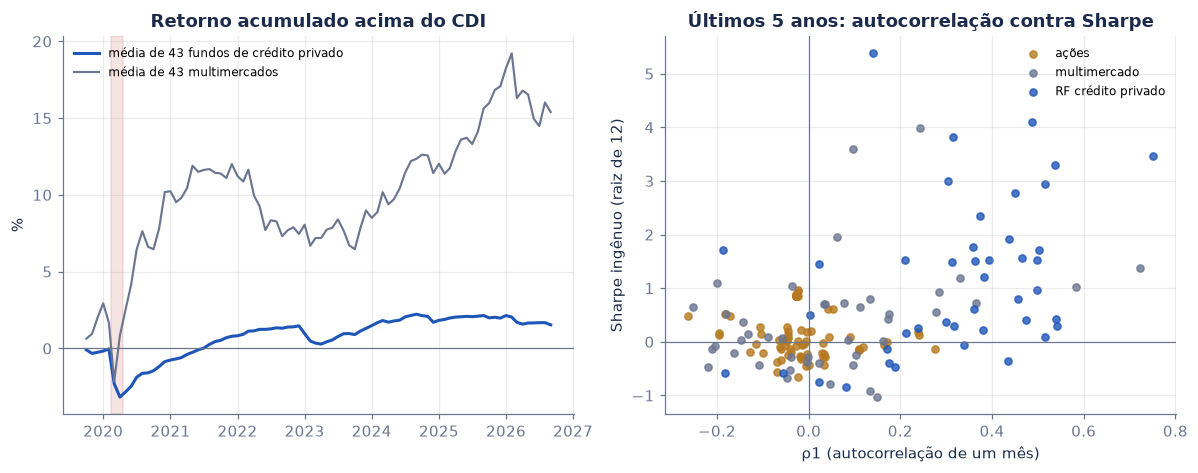

In [27]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4))
eq_cr = (1 + exf.loc[:, classe == "credito"].mean(axis=1)).cumprod() - 1
eq_mm = (1 + exf.loc[:, classe == "multi"].mean(axis=1)).cumprod() - 1
t_ = eq_cr.index.to_timestamp()
a1.plot(t_, 100 * eq_cr, color=BLUE, lw=2, label="média de 43 fundos de crédito privado")
a1.plot(t_, 100 * eq_mm, color=GREY, lw=1.4, label="média de 43 multimercados")
a1.axvspan(pd.Timestamp("2020-02-15"), pd.Timestamp("2020-04-15"), color=RED, alpha=0.12)
a1.axhline(0, color=GREY, lw=0.8)
a1.set(title="Retorno acumulado acima do CDI", ylabel="%"); a1.legend(frameon=False, fontsize=8, loc="upper left")
for k_, c in [("acoes", GOLD), ("multi", GREY), ("credito", BLUE)]:
    d = r5[classe == k_]
    a2.scatter(d["ρ1"], d["Sharpe ingênuo"], color=c, s=22, alpha=0.8, label=nomes[k_])
a2.axvline(0, color=GREY, lw=0.8); a2.axhline(0, color=GREY, lw=0.8)
a2.set(title="Últimos 5 anos: autocorrelação contra Sharpe", xlabel="ρ1 (autocorrelação de um mês)", ylabel="Sharpe ingênuo (raiz de 12)")
a2.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

**Leitura.** Nos últimos cinco anos, o fundo de crédito privado típico marca Sharpe de 0,97 com volatilidade de 0,52 % ao ano, contra Sharpe zero do fundo de ações típico. Parece outro mundo. Mas dois terços dos fundos de crédito têm $\rho_1$ acima de $2/\sqrt{60}$ (mediana 0,36): é a assinatura da cota suave. Corrigido pela (8), o Sharpe mediano cai para 0,60. E a janela de sete anos, que inclui **março de 2020**, derruba o Sharpe ingênuo para 0,27: naquele mês, 42 dos 43 fundos de crédito renderam abaixo do CDI, o mediano 1,88 % abaixo e o pior, 12,39 % abaixo. Um único mês apagou 28 meses do prêmio mediano. É o desenho da put vendida da seção 10: ganho pequeno e constante, perda rara e grande. Nos fundos de ações, $\rho_1$ é zero e a correção não muda nada.

O que fazer com isso, como investidor: comparar Sharpe só dentro da mesma classe; desconfiar de Sharpe alto com volatilidade baixíssima e $\rho_1$ alto (é a cota que é suave, não necessariamente o risco que é baixo); olhar a janela que inclui um mês ruim; e lembrar que cinco anos de cota medem o Sharpe com erro-padrão de 0,45 (seção 4).

## 10. O que o Sharpe esconde: vender put fora do dinheiro

O Sharpe usa só média e desvio-padrão. Duas estratégias com o mesmo Sharpe podem ter riscos completamente diferentes, e a forma clássica de **fabricar** um Sharpe bonito é vender seguro contra quedas (Goetzmann, Ingersoll, Spiegel e Welch, 2007). Simulação simples:

- um índice com retorno extra mensal normal (média 0,5 %, desvio 4,5 %) e, com probabilidade de 1 % ao mês, um **crash** de 30 %;
- todo mês, a estratégia vende uma put de um mês com strike 5 % abaixo do preço, por R\$ 1 de capital (que fica no CDI como garantia);
- o prêmio é **justo**: exatamente o que a put paga em média. O vendedor não tem vantagem nenhuma, e o Sharpe verdadeiro da estratégia é **zero**.

Simulamos 10.000 anos e medimos o Sharpe em cada década.

In [28]:
rng10 = np.random.default_rng(1966)
meses = 12 * 10000
crash = rng10.random(meses) < 0.01
ret_idx = np.exp(rng10.normal(0.005, 0.045, meses) + np.where(crash, math.log(0.70), 0.0)) - 1   # retorno extra do índice no mês
K = 0.95
paga = np.maximum(K - (1 + ret_idx), 0)          # o que a put vendida paga no vencimento, por R$ 1
premio = paga.mean()                             # prêmio justo
pnl = premio - paga                              # resultado mensal do vendedor, acima do CDI
dec_pnl, dec_crash = pnl.reshape(1000, 120), crash.reshape(1000, 120).any(1)
sr_dec = dec_pnl.mean(1) / dec_pnl.std(1) * math.sqrt(12)
assim = ((pnl - pnl.mean()) ** 3).mean() / pnl.std() ** 3
print(f"prêmio justo: {pct(premio, 2)} ao mês; a put termina no dinheiro em {pct((paga > 0).mean(), 1)} dos meses; pior mês {pct(pnl.min(), 1)}")
print(f"Sharpe em 10.000 anos: {br(round(pnl.mean() / pnl.std() * math.sqrt(12), 3) + 0.0, 3)};  assimetria dos meses: {br(assim, 1)} (o índice: {br(((ret_idx - ret_idx.mean()) ** 3).mean() / ret_idx.std() ** 3, 1)})")
print(f"décadas sem crash: {pct(1 - dec_crash.mean())} (0,99^120 = {pct(0.99 ** 120)}) -> Sharpe mediano {br(np.median(sr_dec[~dec_crash]), 2)}, {pct((sr_dec[~dec_crash] > 1).mean())} delas acima de 1")
print(f"décadas com crash: Sharpe mediano {br(np.median(sr_dec[dec_crash]), 2)};  todas as décadas: {pct((sr_dec > 1).mean())} com Sharpe acima de 1")
for mk in [1.3]:
    p2 = mk * paga.mean() - paga; d2 = p2.reshape(1000, 120)
    s2 = d2.mean(1) / d2.std(1) * math.sqrt(12)
    print(f"com prêmio {br(mk, 1)}x o justo: Sharpe em 10.000 anos {br(p2.mean() / p2.std() * math.sqrt(12), 2)}; décadas sem crash: mediana {br(np.median(s2[~dec_crash]), 2)}")
assert abs(pnl.mean()) < 1e-15 and np.median(sr_dec[~dec_crash]) > 0.5

prêmio justo: 0,45 % ao mês; a put termina no dinheiro em 11,4 % dos meses; pior mês −35,9 %
Sharpe em 10.000 anos: 0,000;  assimetria dos meses: −8,7 (o índice: −1,5)
décadas sem crash: 31,4 % (0,99^120 = 29,9 %) -> Sharpe mediano 1,10, 57,6 % delas acima de 1
décadas com crash: Sharpe mediano −0,09;  todas as décadas: 18,1 % com Sharpe acima de 1
com prêmio 1,3x o justo: Sharpe em 10.000 anos 0,18; décadas sem crash: mediana 1,70


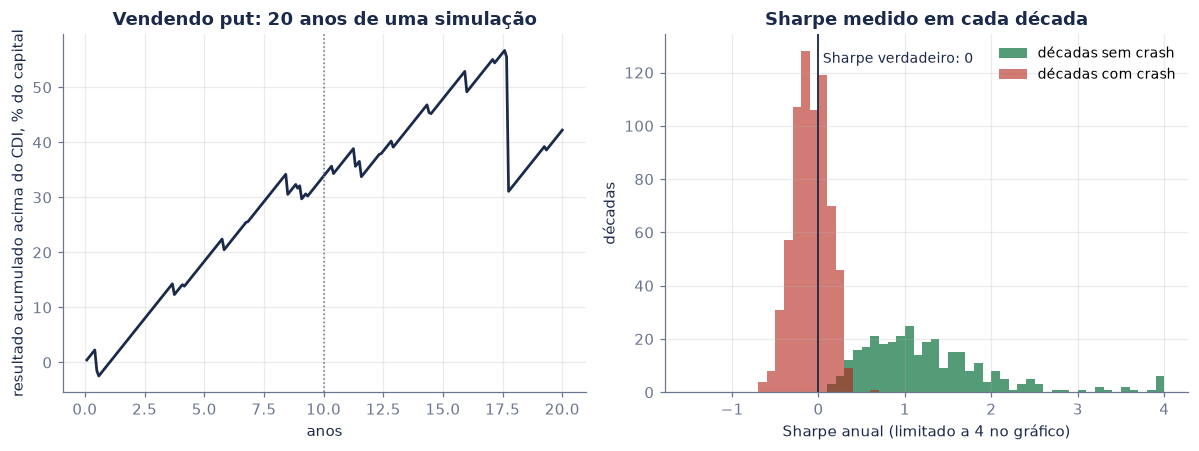

In [29]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
j = int(np.argmax(dec_crash[1:] & ~dec_crash[:-1])) + 1          # uma década sem crash seguida de uma com crash
cam = np.cumsum(pnl[120 * (j - 1):120 * (j + 1)])
a1.plot(np.arange(1, 241) / 12, 100 * cam, color=NAVY, lw=1.8)
a1.axvline(10, color=GREY, ls=":", lw=1)
a1.set(title="Vendendo put: 20 anos de uma simulação", xlabel="anos", ylabel="resultado acumulado acima do CDI, % do capital")
bins = np.linspace(-1.5, 4, 56)
a2.hist(np.clip(sr_dec[~dec_crash], -1.5, 4), bins, color=GREEN, alpha=0.75, label="décadas sem crash")
a2.hist(np.clip(sr_dec[dec_crash], -1.5, 4), bins, color=RED, alpha=0.6, label="décadas com crash")
a2.axvline(0, color=NAVY, lw=1.2); a2.text(0.05, a2.get_ylim()[1] * 0.92, "Sharpe verdadeiro: 0", color=NAVY, fontsize=9)
a2.set(title="Sharpe medido em cada década", xlabel="Sharpe anual (limitado a 4 no gráfico)", ylabel="décadas"); a2.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** Mesmo sem vantagem nenhuma (prêmio justo, Sharpe verdadeiro zero), 31,4 % das décadas não têm crash, e nelas o Sharpe medido tem mediana de 1,10; mais da metade delas passa de 1. Quem olha uma dessas décadas vê um gênio. Com prêmio 30 % acima do justo, o Sharpe verdadeiro é 0,18, mas as décadas sem crash mostram 1,70. A assimetria dos meses do vendedor é −8,7. O Sharpe não vê a assimetria: muitos meses de ganho pequeno e um mês de perda enorme. Para estratégias assim, olhe também a pior perda, a assimetria e o tamanho do maior *drawdown*, e desconfie de qualquer Sharpe medido numa janela sem crise.

## 11. O que o Sharpe não vê

1. **Caudas e assimetria.** Ele resume o risco num desvio-padrão. Na put vendida da seção 10, as décadas sem crash (três em cada dez) mostram Sharpe mediano de 1,10, e o verdadeiro é zero.
2. **O erro de medida.** Uma década de dados mede o Sharpe com erro-padrão de 0,32 (seção 4). Um Sharpe de 0,36 precisa de três décadas para se provar; o do Ibovespa sobre o CDI, de séculos.
3. **A frequência e a autocorrelação.** A raiz de 12 (ou de 252) supõe períodos independentes. Cota suave infla o Sharpe dos fundos de crédito (seções 5 e 9).
4. **O papel na carteira.** O Sharpe de um investimento isolado não diz quanto ele melhora uma carteira: o agitado, pior sozinho, melhora o calmo quando entra com uma pitada (eq. 5).
5. **O custo de alavancar e a taxa segura que muda.** A reta do vídeo supõe emprestar e tomar emprestado a 3 % fixos. No Brasil, o "seguro" é o CDI, que foi de 1,90 % ao ano (ago/2020) a 87,3 % (pico de um dia, em mar/1995), e quem toma emprestado paga spread (seção 8).

### Para praticar (respostas na célula seguinte)

1. Um fundo rende 14 % ao ano com volatilidade de 8 %, e o CDI está em 12 %. Qual o Sharpe? E de uma aplicação metade nesse fundo e metade no CDI?
2. Uma estratégia tem Sharpe verdadeiro de 0,5. Com dados diários, quantos anos são necessários para ela ficar a dois erros-padrão de zero?
3. Um fundo tem Sharpe **mensal** de 0,30 e $\rho_1$ = 0,4 (AR(1)). Qual o Sharpe anual pela raiz de 12? E pela (8)?
4. Você alavanca 3 vezes um investimento com volatilidade de 10 % e Sharpe de 0,8, pagando 2 pontos acima da taxa segura. Qual o Sharpe da posição?
5. Um índice tem volatilidade de 25 % ao ano. Qual o Sharpe mínimo para ele ganhar da taxa segura no acumulado?

In [30]:
print("1)", f"(14 - 12)/8 = {br((0.14 - 0.12) / 0.08, 2)};  50/50: retorno 13 %, volatilidade 4 %, Sharpe (13 - 12)/4 = {br((0.13 - 0.12) / 0.04, 2)} (eq. 3)")
print("2)", f"(2/0,5)² = {br((2 / 0.5) ** 2, 0)} anos (eq. 7)")
print("3)", f"raiz(12) x 0,30 = {br(math.sqrt(12) * 0.30, 3)};  η(12) = {br(eta_ar1(0.4), 3)} -> {br(eta_ar1(0.4) * 0.30, 3)} (eq. 8): a raiz de 12 exagera {pct(math.sqrt(12) / eta_ar1(0.4) - 1, 0)}")
print("4)", f"0,8 - (2/3) x 0,02/0,10 = {br(sr_L(0.8, 3, 0.02, 0.10), 3)} (eq. 10)")
print("5)", f"σ/2 = {br(0.25 / 2, 3)} (eq. 9)")

1) (14 - 12)/8 = 0,25;  50/50: retorno 13 %, volatilidade 4 %, Sharpe (13 - 12)/4 = 0,25 (eq. 3)
2) (2/0,5)² = 16 anos (eq. 7)
3) raiz(12) x 0,30 = 1,039;  η(12) = 2,364 -> 0,709 (eq. 8): a raiz de 12 exagera 47 %
4) 0,8 - (2/3) x 0,02/0,10 = 0,667 (eq. 10)
5) σ/2 = 0,125 (eq. 9)


---

### Resumo de fórmulas

| | Fórmula | Neste notebook |
|---|---|---|
| (1) Anualizar | $\mu = 252\,\bar r$, $\sigma = \sqrt{252}\,s$ | agitado 11,7 % e 24,0 %; calmo 6,0 % e 3,0 % |
| (2) Índice de Sharpe | $SR = (\mu - r_f)/\sigma$ | 0,36 contra 0,99 |
| (3) Mistura com caixa | $SR_w = SR$ para $w > 0$ | 1/8 no agitado: 4,1 %, 3,0 %, 0,36 |
| (4) A meta | $\mu^* = r_f + SR_{\text{calmo}}\,\sigma_{\text{agitado}}$ | 26,8 % |
| (5) Dois independentes | $SR_{\max}^2 = SR_1^2 + SR_2^2$ | 1,06 com 4,4 % no agitado e 95,6 % no calmo |
| (6) Erro-padrão (Lo, 2002) | $\sqrt{(1 + SR^2/2)/T}$ | 0,32 numa década; 0,18 para o Ibovespa desde 1995 |
| (7) Anos para provar | $(2/SR)^2$ | 30,4 anos (agitado), 4,1 (calmo), 427 (Ibovespa sobre o CDI) |
| (8) Anualizar com autocorrelação | $\eta(q) = q/\sqrt{q + 2\sum_k (q-k)\rho_k}$ | +39 % de exagero com $\rho_1$ = 0,35; crédito privado: 0,97 → 0,60 |
| (9) Sharpe e o acumulado | $g - r_f \approx \sigma(SR - \sigma/2)$ | Ibovespa: Sharpe 0,10 < 0,16, perdeu do CDI |
| (10) Alavancar com spread | $SR_L = SR - \frac{L-1}{L}\frac{s}{\sigma}$ | spread de 2,16 pontos iguala o calmo alavancado ao agitado |

### Referências

- GETMANSKY, M.; LO, A. W.; MAKAROV, I. An econometric model of serial correlation and illiquidity in hedge fund returns. *Journal of Financial Economics*, v. 74, n. 3, p. 529–609, 2004.
- GOETZMANN, W.; INGERSOLL, J.; SPIEGEL, M.; WELCH, I. Portfolio performance manipulation and manipulation-proof performance measures. *Review of Financial Studies*, v. 20, n. 5, p. 1503–1546, 2007.
- KÜNSCH, H. R. The jackknife and the bootstrap for general stationary observations. *Annals of Statistics*, v. 17, n. 3, p. 1217–1241, 1989.
- LO, A. W. The statistics of Sharpe ratios. *Financial Analysts Journal*, v. 58, n. 4, p. 36–52, 2002.
- POLITIS, D. N.; ROMANO, J. P. A circular block-resampling procedure for stationary data. In: LEPAGE, R.; BILLARD, L. (ed.). *Exploring the Limits of Bootstrap*. New York: Wiley, 1992.
- SHARPE, W. F. Mutual fund performance. *Journal of Business*, v. 39, n. 1, p. 119–138, 1966.
- SHARPE, W. F. The Sharpe ratio. *Journal of Portfolio Management*, v. 21, n. 1, p. 49–58, 1994.
- TOBIN, J. Liquidity preference as behavior towards risk. *Review of Economic Studies*, v. 25, n. 2, p. 65–86, 1958.
- Dados: Banco Central do Brasil (SGS 12, CDI); CVM (Informe Diário de fundos, dados.cvm.gov.br); Yahoo Finance (Ibovespa e ações).

*Gabriel Pires · [gabrielppires.com](https://gabrielppires.com) · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · O vídeo é inspirado em* Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Simulações nas seções 0 a 5 e 10; dados reais nas seções 6 a 9. Só educação, não é recomendação de investimento.*